# Otimização Inteligente do PNAE — Preparação e Integração de Preços (CONAB)

**Aluna:** Daniela Barreto Araújo

**Orientador:** Renato Cividini Matthiesen

**Curso:** MBA em Data Science & Analytics para Operações

**Projeto:** Otimização inteligente do PNAE: integração de modelos preditivos e programação linear na alimentação escolar

**Módulo:** 3 — *Ingestão, ETL e análise exploratória dos preços dos alimentos*

> Este notebook é a continuação direta do **Módulo 1 (tratamento da base de alimentos do PNAE)** e insumo direto para os **Módulo 4 (modelagem Regras PNAE de Restrições para o Otimizador)** e **Módulo 5 (modelagem por Programação Linear — Problema da Dieta)**. O objetivo aqui é produzir, para cada alimento elegível do cardápio PNAE, um **preço de referência por kg**, rastreável e auditável, a partir do cruzamento de três bases distintas da CONAB.

---


## Sumário

1. [Objetivo, escopo e fontes de dados](#1)
2. [Configuração do ambiente](#2)
3. [Carregamento da base de alimentos do PNAE (Módulo 1)](#3)
4. [Ingestão e tratamento das três fontes de preços da CONAB](#4)
   - 4.1 [Tabela 1 — Preço Mensal por UF (Conab1)](#4-1)
   - 4.2 [Tabela 2 — Preço Mínimo / PGPM (Conab2)](#4-2)
   - 4.3 [Tabela 3 — PROHORT Mensal (Conab3)](#4-3)
5. [Cruzamento inteligente PNAE × CONAB (matching semântico)](#5)
   - 5.1 [Normalização textual](#5-1)
   - 5.2 [Mapeamentos curados](#5-2)
   - 5.3 [Classificação de elegibilidade de Agricultura Familiar](#5-3)
   - 5.4 [Conversão de unidades comerciais para kg](#5-4)
   - 5.5 [Matching semântico por similaridade (TF-IDF)](#5-5)
   - 5.6 [Pré-processamento específico por fonte](#5-6)
   - 5.7 [Hierarquia de fontes e função de busca](#5-7)
6. [Execução do pipeline de matching](#6)
7. [Tratamento de outliers (IQR)](#7)
8. [Análise de sazonalidade](#8)
9. [Resumo final por produto (insumo do otimizador)](#9)
   - 9B [Fallback de preço: planilha manual](#9b)
   - 9C [Consolidação da base final de produtos aptos ao solver](#9c)
   - 9D [Análise de sensibilidade do desconto de varejo](#9d)
10. [Cobertura estimada de Agricultura Familiar](#10)
11. [Visualizações](#11)
12. [Exportação dos arquivos de saída](#12)
13. [Conclusão, limitações e próximos passos](#13)

---



<a id="1"></a>
## 1. Objetivo, escopo e fontes de dados

**Objetivo:** para cada alimento elegível do cardápio PNAE (`pode_precificar == True`), obter um **preço de referência em R$/kg**, com rastreabilidade da fonte, nível de confiança do match e sinalização de Agricultura Familiar (AF) — insumo direto da função-objetivo e das restrições de custo do modelo de Programação Linear do Módulo 3.

**Ferramental:** Jupyter Notebook via Visual Studio Code. Os comandos de instalação de bibliotecas são omitidos; ao reproduzir o notebook, instale as dependências (`pip install`) antes de importar.

**Fontes de dados**

| Fonte | Descrição | Uso no projeto |
|---|---|---|
| [Planilha PNAE (FNDE)](https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/pnae/media-pnae/Planilha_PlanPNAE_versao_4atualizada221121.xlsx) | Composição nutricional dos alimentos do cardápio. Já tratada no Módulo 1 → `pnae_alimentos_naoproibidos.csv` | Lista de referência a ser precificada |
| [Portal de Informações CONAB](https://portaldeinformacoes.conab.gov.br/download-arquivos.html) | Portal de origem dos três arquivos de preço abaixo | — |
| [PrecosMensalUF.txt](https://portaldeinformacoes.conab.gov.br/downloads/arquivos/PrecosMensalUF.txt) | Preços mensais de atacado/varejo por UF | **Conab1** — fonte primária |
| [PrecoMinimo.txt](https://portaldeinformacoes.conab.gov.br/downloads/arquivos/PrecoMinimo.txt) | Política de Garantia de Preços Mínimos (PGPM) | **Conab2** — piso de preço e sinalizador de AF |
| [ProhortMensal.txt](https://portaldeinformacoes.conab.gov.br/downloads/arquivos/ProhortMensal.txt) | Comercialização nas CEASAs, com origem por município/UF | **Conab3** — canal habitual de compra das prefeituras |

**Etapas do processo (ETL)**

- **Ingestão:** download automatizado (com cache local) dos três arquivos da CONAB.
- **Tratamento:** padronização de colunas, conversão de tipos numéricos (formato brasileiro `.`/`,`), filtro para o estado da Bahia, remoção de linhas em branco/duplicadas e de registros inválidos (cabeçalhos residuais).
- **Enriquecimento:** normalização textual, matching semântico (TF-IDF) entre os produtos do PNAE e os produtos das três fontes CONAB, conversão de todas as unidades comerciais para R$/kg, classificação de Agricultura Familiar e cálculo de sazonalidade mensal.
- **Consolidação:** hierarquia de prioridade entre fontes/níveis de comercialização define o preço de referência final de cada produto.

---


<a id="2"></a>
## 2. Configuração do ambiente

### 2.1 Bibliotecas e configurações visuais


In [2]:
# importação das bibliotecas
import pandas as pd
import numpy as np

import requests
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Para lidar com caracteres acentuados
import unicodedata

# Para normalização semântica e matching
import re

# Matching semântico por similaridade TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from openpyxl import load_workbook
import warnings

# Silenciar apenas avisos específicos do openpyxl
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

# Configurações visuais
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

plt.rcParams["figure.figsize"] = (12, 6)
sns.set_style("whitegrid")

### 2.2 Estrutura de pastas

Padrão de projeto de dados: `data/input/` guarda os arquivos originais baixados (cache local, para não depender de conexão em execuções futuras) e `data/output/` recebe todos os artefatos gerados por este notebook (CSVs tratados e gráficos).


In [3]:
# Padrão de pastas para projetos de dados
input_folder  = './data/input/'
output_folder = './data/output/'

for folder in [input_folder, output_folder]:
    os.makedirs(folder, exist_ok=True)

<a id="3"></a>
## 3. Carregamento da base de alimentos do PNAE (Módulo 1)

Carrega `pnae_alimentos_naoproibidos.csv`, já enriquecida no Módulo 1 com macronutrientes, micronutrientes, restrições e clusterização nutricional. Aqui filtramos apenas os alimentos marcados como elegíveis à precificação (`pode_precificar == True`) e criamos `produto_busca`, a chave textual usada em todo o matching com as fontes CONAB.


In [4]:
# Criar DataFrame
df = pd.read_csv(output_folder + 'pnae_alimentos_naoproibidos.csv', low_memory=False)

df = df[df['pode_precificar'] == True].copy()
print(f"Alimentos elegíveis para precificação: {len(df)}")

# Coluna unificada para busca — usa produto_base já limpo
df['produto_busca'] = df['produto_base'].astype(str).str.strip()

# NOTA (set/2026): o número de alimentos elegíveis (linhas) tende a ser maior
# que o número de produto_busca únicos, pois preparações/variações diferentes
# de um mesmo alimento (ex.: "arroz branco cozido" e "arroz branco refogado")
# compartilham a mesma chave de busca textual. Registrar essa diferença
# explicitamente evita a aparência de inconsistência ao comparar esta
# contagem com a base final do Bloco 12C (produtos únicos aptos ao solver).
print(f"Produto_busca únicos: {df['produto_busca'].nunique()} "
      f"(chave textual usada no matching — ver nota acima sobre a diferença "
      f"em relação ao total de linhas)")

print(f"Processamento concluído. DataFrame criado com {len(df)} linhas e {len(df.columns)} colunas.")
display(df.head())


Alimentos elegíveis para precificação: 435
Produto_busca únicos: 426 (chave textual usada no matching — ver nota acima sobre a diferença em relação ao total de linhas)
Processamento concluído. DataFrame criado com 435 linhas e 47 colunas.


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae,pode_precificar,motivo_exclusao,descricao_normalizada,produto_base,categoria,quantidade_embalagem,unidade_medida,norm_calcio,norm_ferro,norm_retinol,norm_vitamina_c,sdn_score,relacao_proteina_caloria,estado_preparo,origem,is_restrito,cluster_nutricional,pca_1,pca_2,perfil_processado_score,z_energia,z_proteina,z_lipideos,z_carboidratos,z_calcio,z_ferro,z_retinol,z_vitamina_c,z_sodio,dominancia_nutricional,score_processamento,dominancia_count,is_ingrediente,motivo_ingrediente,produto_busca
0,"Abacate, cru",96.154709,402.311301,1.239130,8.396667,6.030870,7.916667,0.206667,61.20,8.660000,0.000000,Sem restrição,True,NaN,abacate cru,abacate,frutas,NaN,kg,0.005023,0.002111,0.000553,0.009199,0.000174,0.012886,cru,Vegetal,False,2,-1.039337,0.114239,0.000000,-0.559625,-0.679460,-0.050010,-0.619820,-0.377818,-0.279775,-0.083106,-0.150011,-0.173607,-1.570170,0.429429,0,False,NaN,abacate
3,"Abacaxi, cru",48.322213,202.180139,0.858696,0.123333,12.334638,22.433333,0.256667,2.30,34.623333,0.000000,Sem restrição,True,NaN,abacaxi cru,abacaxi,frutas,NaN,kg,0.014234,0.002622,0.000021,0.036780,0.001088,0.017767,cru,Vegetal,False,2,-1.183124,-0.330701,0.000000,-0.816827,-0.719241,-0.301885,-0.395545,-0.302571,-0.272421,-0.093383,0.258552,-0.173607,-1.129063,0.259979,1,False,NaN,abacaxi
7,"Abacaxi, polpa, congelada",30.591799,127.996088,0.466667,0.113333,7.798667,13.538000,0.357333,2.00,1.246667,1.236333,Sem restrição,True,NaN,abacaxi polpa congelada,abacaxi polpa,sucos_bebidas,NaN,kg,0.008590,0.003650,0.000018,0.001324,0.000430,0.015250,congelado,Outros/Processados,False,2,-1.270927,-0.132950,0.257875,-0.912165,-0.760233,-0.302190,-0.556925,-0.348680,-0.257614,-0.093435,-0.266668,-0.173165,-1.726630,0.466455,0,False,NaN,abacaxi polpa
8,"Abacaxi, polpa, congelada",34.000000,142.256000,0.470000,0.120000,7.800000,13.600000,0.360000,2.26,1.250000,1.240000,Sem restrição,True,NaN,abacaxi polpa congelada,abacaxi polpa,sucos_bebidas,NaN,kg,0.008629,0.003677,0.000020,0.001328,0.000390,0.013819,congelado,Outros/Processados,False,2,-1.260520,-0.125664,0.286803,-0.893839,-0.759884,-0.301987,-0.556878,-0.348358,-0.257222,-0.093390,-0.266616,-0.173164,-1.725471,0.518095,0,False,NaN,abacaxi polpa
11,"Abadejo, filé, congelado, cru",59.113033,247.328931,13.083333,0.360000,0.000000,10.174667,0.106000,0.00,0.000000,78.515000,Sem restrição,True,NaN,abadejo file congelado cru,abadejo file,proteinas_animais,NaN,kg,0.006456,0.001083,0.000000,0.000000,0.000125,0.221290,cru,Animal,False,2,-0.840721,-0.088964,3.295569,-0.758803,0.559028,-0.294680,-0.834386,-0.366114,-0.294581,-0.093784,-0.286286,-0.145513,-0.481737,3.337543,0,False,NaN,abadejo file


**Verificação exploratória (não utilizada nas etapas seguintes):** amostra aleatória de 1% da base, usada apenas para inspeção visual rápida durante o desenvolvimento.


In [5]:
# Amostra aleatória de 1% dos dados para testes iniciais
df_sample = df.sample(frac=0.01, random_state=42)
print(df_sample.shape)
display(df_sample)

(4, 47)


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae,pode_precificar,motivo_exclusao,descricao_normalizada,produto_base,categoria,quantidade_embalagem,unidade_medida,norm_calcio,norm_ferro,norm_retinol,norm_vitamina_c,sdn_score,relacao_proteina_caloria,estado_preparo,origem,is_restrito,cluster_nutricional,pca_1,pca_2,perfil_processado_score,z_energia,z_proteina,z_lipideos,z_carboidratos,z_calcio,z_ferro,z_retinol,z_vitamina_c,z_sodio,dominancia_nutricional,score_processamento,dominancia_count,is_ingrediente,motivo_ingrediente,produto_busca
352,"Maria mole, coco queimado",306.631897,1282.947857,3.934950,0.089333,75.059383,19.456333,0.471333,0.0,0.0,14.00,Oferta limitada para > 3 anos e proibida para ...,True,NaN,maria mole coco queimado,maria mole coco queimado,doces_acucares,NaN,kg,0.012345,0.004814,0.000000,0.0,0.000056,0.012832,natural_ou_outros,Outros/Processados,True,4,0.504614,0.418951,8.698865,0.572137,-0.397572,-0.302920,1.836071,-0.318002,-0.240847,-0.093784,-0.286286,-0.168598,-1.336491,9.320213,0,False,NaN,maria mole coco queimado
100,"Cajá, polpa, congelada",27.000000,112.968000,0.590000,0.170000,6.380000,9.170000,0.330000,107.0,0.0,6.95,Sem restrição,True,NaN,caja polpa congelada,caja polpa,sucos_bebidas,NaN,kg,0.005819,0.003371,0.000967,0.0,0.000363,0.021844,congelado,Outros/Processados,False,2,-1.303281,-0.119818,1.180189,-0.931479,-0.747337,-0.300464,-0.607399,-0.371321,-0.261635,-0.075114,-0.286286,-0.171120,-1.741693,1.350000,0,False,NaN,caja polpa
140,"Carne, bovina, flanco, sem gordura, cru",141.460100,591.869058,19.996667,6.216667,0.000000,2.813333,1.580000,2.0,0.0,54.00,Sem restrição,True,NaN,carne bovina flanco sem gordura cru,carne bovina flanco sem gordura,proteinas_animais,NaN,kg,0.001785,0.016139,0.000018,0.0,0.000126,0.141349,cru,Animal,False,1,-0.221886,0.068594,3.638123,-0.316013,1.281921,-0.116379,-0.834386,-0.404271,-0.077780,-0.093435,-0.286286,-0.154285,0.420149,3.705496,1,False,NaN,carne bovina flanco sem gordura
318,"Linguiça, calabresa, fininha, crua",256.000000,1071.104000,18.000000,20.000000,1.000000,6.940000,1.000000,0.0,0.0,840.00,Oferta limitada para > 3 anos e proibida para ...,True,NaN,linguica calabresa fininha crua,linguica calabresa fininha,carneos,NaN,kg,0.004404,0.010215,0.000000,0.0,0.000057,0.070310,cru,Animal,True,1,0.122952,0.595449,113.178947,0.299883,1.073139,0.303243,-0.798808,-0.382880,-0.163088,-0.093784,-0.286286,0.126967,0.147101,113.313684,1,False,NaN,linguica calabresa fininha


<a id="4"></a>
## 4. Ingestão e tratamento das três fontes de preços da CONAB

As três tabelas a seguir serão as referências de preço. Cada uma é baixada (com cache local em `data/input/`), padronizada (nomes de coluna, tipos numéricos) e filtrada para a Bahia, mantendo apenas as colunas relevantes ao projeto.


<a id="4-1"></a>
### 4.1 Tabela 1 — Preço Mensal por UF (Conab1)

Fonte principal de preços de atacado e varejo, com série histórica mensal por estado. Os níveis **ATACADO** e **VAREJO** são mantidos separados propositalmente — a hierarquia de prioridade entre eles só é aplicada na etapa de matching (seção 5.7), e não aqui.


In [6]:
# Definição dos caminhos e URLs
URL1 = "https://portaldeinformacoes.conab.gov.br/downloads/arquivos/PrecosMensalUF.txt"
local_file_path = input_folder + "dataset_conab1_original.csv"

if os.path.exists(local_file_path):
    print(f"Carregando dados localmente de: {local_file_path}")
    df_precos_conab1 = pd.read_csv(local_file_path, sep=",", encoding="utf-8-sig", low_memory=False)
else:
    print("Arquivo local não encontrado. Baixando dados da CONAB...")
    df_precos_conab1 = pd.read_csv(URL1, sep=";", encoding="latin1", decimal=",", low_memory=False)
    os.makedirs(os.path.dirname(local_file_path), exist_ok=True)
    df_precos_conab1.to_csv(local_file_path, index=False, encoding='utf-8-sig')
    print(f"Dados salvos localmente em: {local_file_path}")

display(df_precos_conab1.head())

# Padronização de nomes de colunas
df_precos_conab1.columns = (
    df_precos_conab1.columns
    .str.strip().str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

# Converter colunas numéricas
for col in df_precos_conab1.columns:
    if df_precos_conab1[col].dtype == "object":
        try:
            df_precos_conab1[col] = (
                df_precos_conab1[col].astype(str)
                .str.replace(".", "", regex=False)
                .str.replace(",", ".", regex=False)
            )
            df_precos_conab1[col] = pd.to_numeric(df_precos_conab1[col])
        except:
            pass

print(df_precos_conab1.shape)
display(df_precos_conab1.head())

Carregando dados localmente de: ./data/input/dataset_conab1_original.csv


,produto,classificao_produto,id_produto,uf,regiao,ano,mes,dsc_nivel_comercializacao,valor_produto_kg
0,00-18-18,NÃO INFORMADO,10224,MT,CENTRO-OESTE,2025,7,PREÇO PAGO PELO PRODUTOR ...,2.27
1,00-18-18,NÃO INFORMADO,10224,MT,CENTRO-OESTE,2025,11,PREÇO PAGO PELO PRODUTOR ...,2.32
2,00-18-18,NÃO INFORMADO,10224,MT,CENTRO-OESTE,2026,3,PREÇO PAGO PELO PRODUTOR ...,2.41
3,00-20-20,NÃO INFORMADO,4466,MT,CENTRO-OESTE,2025,7,PREÇO PAGO PELO PRODUTOR ...,2.33
4,00-20-20,NÃO INFORMADO,4466,MT,CENTRO-OESTE,2025,11,PREÇO PAGO PELO PRODUTOR ...,2.39


(24218, 9)


,produto,classificao_produto,id_produto,uf,regiao,ano,mes,dsc_nivel_comercializacao,valor_produto_kg
0,00-18-18,NÃO INFORMADO,10224,MT,CENTRO-OESTE,2025,7,PREÇO PAGO PELO PRODUTOR ...,2.27
1,00-18-18,NÃO INFORMADO,10224,MT,CENTRO-OESTE,2025,11,PREÇO PAGO PELO PRODUTOR ...,2.32
2,00-18-18,NÃO INFORMADO,10224,MT,CENTRO-OESTE,2026,3,PREÇO PAGO PELO PRODUTOR ...,2.41
3,00-20-20,NÃO INFORMADO,4466,MT,CENTRO-OESTE,2025,7,PREÇO PAGO PELO PRODUTOR ...,2.33
4,00-20-20,NÃO INFORMADO,4466,MT,CENTRO-OESTE,2025,11,PREÇO PAGO PELO PRODUTOR ...,2.39


In [7]:
# Remover linhas em branco e duplicadas
df_precos_conab1 = df_precos_conab1.dropna(how='all').drop_duplicates()
print(f"Shape após deduplicação: {df_precos_conab1.shape}")

# Limpar campo produto
df_precos_conab1["produto"] = df_precos_conab1["produto"].astype(str).str.strip()

# Remover linhas com padrão de código xx-xx-xx (cabeçalhos ou lixo)
df_precos_conab1 = df_precos_conab1[
    ~df_precos_conab1["produto"].str.contains(
        r"^[A-Za-z0-9]{2}-[A-Za-z0-9]{2}-[A-Za-z0-9]{2}", regex=True, na=False
    )
]

# Limpar nível de comercialização
df_precos_conab1["dsc_nivel_comercializacao"] = (
    df_precos_conab1["dsc_nivel_comercializacao"].astype(str).str.strip()
)
print("Níveis de comercialização disponíveis:")
display(df_precos_conab1["dsc_nivel_comercializacao"].value_counts())

# IMPORTANTE: manter ATACADO e VAREJO separados — a hierarquia de prioridade
# será aplicada na etapa de matching. Não filtrar nem mesclar aqui.
df_precos_conab1 = df_precos_conab1[
    df_precos_conab1['dsc_nivel_comercializacao'].isin(['ATACADO', 'VAREJO'])
]

# Padronizar UF e filtrar Bahia
df_precos_conab1["uf"] = df_precos_conab1["uf"].astype(str).str.strip().str.upper()
df_precos_conab1 = df_precos_conab1[df_precos_conab1['uf'] == 'BA']

# Garantir que ano_mes seja numérico (AAAAMM)
if 'ano_mes' in df_precos_conab1.columns:
    df_precos_conab1['ano_mes'] = pd.to_numeric(df_precos_conab1['ano_mes'], errors='coerce')
    df_precos_conab1['mes'] = df_precos_conab1['ano_mes'] % 100
    df_precos_conab1['ano'] = df_precos_conab1['ano_mes'] // 100

df_precos_conab1 = df_precos_conab1.reset_index(drop=True)
print(f"Shape final: {df_precos_conab1.shape}")
display(df_precos_conab1.head(10))

Shape após deduplicação: (24175, 9)
Níveis de comercialização disponíveis:


dsc_nivel_comercializacao
PREÇO PAGO PELO PRODUTOR      8369
PREÇO RECEBIDO P/ PRODUTOR    6673
VAREJO                        5089
ATACADO                       3843
Name: count, dtype: int64

Shape final: (295, 9)


,produto,classificao_produto,id_produto,uf,regiao,ano,mes,dsc_nivel_comercializacao,valor_produto_kg
0,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,5,ATACADO,3.81
1,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,5,VAREJO,3.93
2,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,6,VAREJO,3.87
3,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,6,ATACADO,3.78
4,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,7,ATACADO,3.82
5,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,7,VAREJO,3.92
6,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,8,VAREJO,3.81
7,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,8,ATACADO,3.71
8,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,9,ATACADO,3.54
9,ACUCAR,CRISTAL,4218,BA,NORDESTE,2025,9,VAREJO,4.16


Persistência do dataset tratado (usado como cache e para auditoria fora do notebook):


In [8]:
df_precos_conab1.to_csv(
    output_folder + "dataset_conab1_transformado.csv",
    index=False, encoding='utf-8-sig'
)
print("Dataset 1 salvo com sucesso.")

Dataset 1 salvo com sucesso.


Inspeção da lista de produtos disponíveis após o filtro por Bahia — referência para conferir a cobertura dos mapeamentos curados definidos na seção 5.2.


In [9]:
# Visualizar produtos disponíveis no Conab1 (BA)
print("Produtos únicos no Conab1 (BA):")
print(sorted(df_precos_conab1['produto'].unique()))

Produtos únicos no Conab1 (BA):
['ACUCAR', 'ARROZ', 'BANANA', 'CAFE', 'CARNE BOVINA', 'CARNE DE FRANGO', 'FARINHA DE MANDIOCA', 'FARINHA DE TRIGO', 'FEIJAO', 'FLOCOS DE MILHO', 'FUBA DE MILHO', 'LEITE DE VACA', 'MACARRAO', 'MANTEIGA', 'MILHO', 'OLEO DE SOJA', 'OVOS DE GALINHA', 'PAO', 'TOMATE']


<a id="4-2"></a>
### 4.2 Tabela 2 — Preço Mínimo / PGPM (Conab2)

Preços mínimos garantidos pelo governo federal (Política de Garantia de Preços Mínimos — PGPM). **CORREÇÃO METODOLÓGICA (set/2026):** diferente do que se assumia em versões anteriores deste notebook, a PGPM **não é exclusiva da Agricultura Familiar** — é um instrumento de preço mínimo aberto a produtores em geral, e a lista de produtos cobertos na Bahia inclui inclusive commodities tipicamente patronais/extrativistas (ex.: algodão em pluma, borracha natural cultivada, sisal). Nenhuma das colunas desta tabela identifica o perfil do fornecedor (DAP/CAF). Por isso, a presença de um produto no PGPM é tratada como **evidência de elegibilidade categórica** (`is_af = True`, `base_af = 'pgpm'`) — não como confirmação de origem — na classificação da seção 5.3. Ver seção 13 (Limitações) para a justificativa completa.



In [10]:
URL2 = "https://portaldeinformacoes.conab.gov.br/downloads/arquivos/PrecoMinimo.txt"
local_file_path = input_folder + "dataset_conab2_original.csv"

if os.path.exists(local_file_path):
    print(f"Carregando dados localmente de: {local_file_path}")
    df_precos_conab2 = pd.read_csv(local_file_path, sep=",", encoding="utf-8-sig", low_memory=False)
else:
    print("Arquivo local não encontrado. Baixando dados da CONAB...")
    df_precos_conab2 = pd.read_csv(URL2, sep=";", encoding="latin1", decimal=",", low_memory=False)
    os.makedirs(os.path.dirname(local_file_path), exist_ok=True)
    df_precos_conab2.to_csv(local_file_path, index=False, encoding='utf-8-sig')
    print(f"Dados salvos localmente em: {local_file_path}")

display(df_precos_conab2.head())

df_precos_conab2.columns = (
    df_precos_conab2.columns
    .str.strip().str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

for col in df_precos_conab2.columns:
    if df_precos_conab2[col].dtype == "object":
        try:
            df_precos_conab2[col] = (
                df_precos_conab2[col].astype(str)
                .str.replace(".", "", regex=False)
                .str.replace(",", ".", regex=False)
            )
            df_precos_conab2[col] = pd.to_numeric(df_precos_conab2[col])
        except:
            pass

print(df_precos_conab2.shape)
display(df_precos_conab2.head())

Carregando dados localmente de: ./data/input/dataset_conab2_original.csv


,descricao_produto_preco_minimo,id_produto,uf,regionalizacao,ano_inicio_vigencia,mes_incio_vigencia,ano_termino_vigencia,mes_termino_vigencia,preco,dsc_unidade_comercializacao,nome_normativo,url
0,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2014,7,2015,6,1.11,kg ...,"PORTARIA Nº 190, DE 9 DE",NI ...
1,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2015,7,2016,6,1.18,kg ...,"PORTARIA Nº 190, DE 9 DE",NI ...
2,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2016,7,2017,6,1.29,kg ...,"PORTARIA Nº 123, DE 5 DE JULHO",http://biblioteca.conab.gov.br/phl82/pdf/legis...
3,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2017,7,2017,12,1.29,kg ...,"PORTARIA Nº 1.577, DE 17 DE JU",http://biblioteca.conab.gov.br/phl82/pdf/legis...
4,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2018,1,2018,12,1.60,kg ...,"PORTARIA Nº 14, DE 3 DE JANEIR",http://biblioteca.conab.gov.br/phl82/pdf/legis...


(9485, 12)


,descricao_produto_preco_minimo,id_produto,uf,regionalizacao,ano_inicio_vigencia,mes_incio_vigencia,ano_termino_vigencia,mes_termino_vigencia,preco,dsc_unidade_comercializacao,nome_normativo,url
0,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2014,7,2015,6,1.11,kg ...,"PORTARIA Nº 190, DE 9 DE",NI ...
1,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2015,7,2016,6,1.18,kg ...,"PORTARIA Nº 190, DE 9 DE",NI ...
2,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2016,7,2017,6,1.29,kg ...,"PORTARIA Nº 123, DE 5 DE JULHO",http://biblioteca.conab.gov.br/phl82/pdf/legis...
3,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2017,7,2017,12,1.29,kg ...,"PORTARIA Nº 1.577, DE 17 DE JU",http://biblioteca.conab.gov.br/phl82/pdf/legis...
4,AÇAÍ (FRUTO) - PRODUTO EXTRATIVO,6331,AC,AC,2018,1,2018,12,1.60,kg ...,"PORTARIA Nº 14, DE 3 DE JANEIR",http://biblioteca.conab.gov.br/phl82/pdf/legis...


**Normalização de unidade comercial → R$/kg (exploração inicial).** Diferente do Conab1 (já em R$/kg), o Conab2 traz o preço por unidade comercial (saca, caixa, tonelada etc.). A tabela `FATOR_PARA_KG` abaixo mapeia os padrões mais comuns da CONAB, como primeira exploração desse problema.

**Verificação exploratória (não utilizada nas etapas seguintes):** esta célula foi o primeiro esboço da lógica de conversão de unidades, mantida aqui por transparência do processo de desenvolvimento. Ela é **inteiramente substituída** pela versão definitiva da seção 5.4 (Bloco 4), que generaliza o tratamento para também reconhecer unidades de volume (`L`, `LT`) com densidade específica por produto. Os nomes das colunas geradas aqui foram marcados com sufixo `_exploratorio` para deixar explícito que não alimentam o pipeline principal — o `preco_kg` efetivamente usado no matching (Bloco 6/7) é recalculado do zero em `_preparar_conab2()`, a partir da função `extrair_fator_kg()` definida na seção 5.4.



In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# NORMALIZAÇÃO DE UNIDADE — Conab2 (PGPM) — VERSÃO EXPLORATÓRIA
# Não utilizada nas etapas seguintes — ver nota na célula de markdown acima.
# A versão definitiva está na seção 5.4 (Bloco 4, extrair_fator_kg com 2 args).
# ═══════════════════════════════════════════════════════════════════════════

# Tabela de conversão preliminar: padrão CONAB → fator para chegar em kg
FATOR_PARA_KG_EXPLORATORIO = {
    # Sacas / bags
    'SC 60KG': 60, 'SC 50KG': 50, 'SC 30KG': 30, 'SC 20KG': 20,
    'SC 10KG': 10, 'SC 5KG': 5,
    # Caixas de hortifrúti
    'CX 23KG': 23, 'CX 20KG': 20, 'CX 18KG': 18, 'CX 15KG': 15,
    'CX 12KG': 12, 'CX 10KG': 10, 'CX 5KG': 5,
    # Unidades já em kg
    'KG': 1, 'R$/KG': 1,
    # Tonelada
    'T': 1000, 'TON': 1000,
}

def _extrair_fator_kg_exploratorio(unidade: str) -> float:
    # Versão preliminar (1 argumento, sem suporte a líquidos). Mantida
    # apenas para referência histórica — NÃO é chamada em nenhuma etapa
    # posterior do pipeline (ver seção 5.4 para a versão definitiva).
    unidade = str(unidade).strip().upper()
    if unidade in FATOR_PARA_KG_EXPLORATORIO:
        return FATOR_PARA_KG_EXPLORATORIO[unidade]
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*KG', unidade)
    if match:
        return float(match.group(1).replace(',', '.'))
    return float('nan')

col_preco_conab2 = 'preco'        # ← ajuste se o nome da coluna for diferente
col_unid_conab2  = 'dsc_unidade_comercializacao'

df_precos_conab2['fator_kg_exploratorio'] = (
    df_precos_conab2[col_unid_conab2].apply(_extrair_fator_kg_exploratorio)
)

# Auditoria antes da normalização
sem_fator = df_precos_conab2[df_precos_conab2['fator_kg_exploratorio'].isna()]
if not sem_fator.empty:
    print("Unidades sem mapeamento (verificar manualmente):")
    display(sem_fator[col_unid_conab2].value_counts())

# Aplicar conversão (apenas para inspeção — não é a coluna "preco_kg" final)
df_precos_conab2['preco_kg_exploratorio'] = (
    df_precos_conab2[col_preco_conab2] / df_precos_conab2['fator_kg_exploratorio']
)

# Sanity check pós-conversão (valores preliminares, não os finais do pipeline)
print("\nEstatísticas de preco_kg_exploratorio (versão preliminar, não final):")
display(df_precos_conab2.groupby(col_unid_conab2)['preco_kg_exploratorio'].describe())


Unidades sem mapeamento (verificar manualmente):


dsc_unidade_comercializacao
l                                                               324
Name: count, dtype: int64


Estatísticas de preco_kg_exploratorio (versão preliminar, não final):


,count,mean,std,min,25%,50%,75%,max
dsc_unidade_comercializacao,,,,,,,,
15 kg,1095.0,2.638754,2.371976,0.210000,0.448667,1.920000,3.748000,8.030000
"40,8 kg",351.0,0.447951,0.152219,0.280637,0.300980,0.390931,0.584069,0.704902
50 kg,26.0,0.874938,0.286579,0.516000,0.699400,0.792600,1.212200,1.309400
60 kg,3203.0,2.255086,2.719224,0.025485,0.466500,1.275000,3.020500,13.208833
kg,4135.0,3.010926,4.206527,0.010000,1.050000,1.980000,3.240000,40.520000
l,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
t,351.0,0.292187,0.124670,0.170000,0.201160,0.237110,0.401640,0.548760


Filtro para Bahia, limpeza final e remoção de colunas de baixo valor analítico para o projeto:


In [12]:
df_precos_conab2 = df_precos_conab2.dropna(how='all').drop_duplicates()

df_precos_conab2["descricao_produto_preco_minimo"] = (
    df_precos_conab2["descricao_produto_preco_minimo"].astype(str).str.strip()
)

df_precos_conab2["uf"] = df_precos_conab2["uf"].astype(str).str.strip().str.upper()
df_precos_conab2 = df_precos_conab2[df_precos_conab2['uf'] == 'BA']

# Remover colunas de baixo valor para o projeto
colunas_para_remover = [c for c in ['regionalizacao', 'nome_normativo', 'url'] if c in df_precos_conab2.columns]
df_precos_conab2 = df_precos_conab2.drop(columns=colunas_para_remover)

df_precos_conab2 = df_precos_conab2.reset_index(drop=True)
print(f"Shape final: {df_precos_conab2.shape}")

print("\nUnidades de comercialização disponíveis:")
display(df_precos_conab2['dsc_unidade_comercializacao'].value_counts())
print("\nProdutos disponíveis no Conab2 (BA):")
print(sorted(df_precos_conab2['descricao_produto_preco_minimo'].unique()))

Shape final: (482, 11)

Unidades de comercialização disponíveis:


dsc_unidade_comercializacao
kg                                                              186
60 kg                                                           183
15 kg                                                            75
40,8 kg                                                          13
t                                                                13
l                                                                12
Name: count, dtype: int64


Produtos disponíveis no Conab2 (BA):
['', 'ALGODÃO EM CAROÇO', 'ALGODÃO EM PLUMA', 'ANDIROBA (AMÊNDOA) - PRODUTO EXTRATIVO', 'ARROZ LONGO EM CASCA', 'ARROZ LONGO FINO EM CASCA', 'AÇAÍ (FRUTO) - PRODUTO EXTRATIVO', 'BABAÇU (AMÊNDOA) - PRODUTO EXTRATIVO', 'BORRACHA NATURAL CULTIVADA', 'CACAU CULTIVADO (AMÊNDOA)', 'CAFÉ ARÁBICA', 'CAFÉ CONILON', 'CAROÇO DE ALGODÃO', 'FARINHA DE MANDIOCA', 'FEIJÃO CORES', 'FEIJÃO PRETO', 'GOMA/POLVILHO', 'LARANJA', 'LEITE', 'LÁTEX', 'MACAÚBA (FRUTO) - PRODUTO EXTRATIVO', 'MANGABA (FRUTO) - PRODUTO EXTRATIVO', 'MILHO', 'PEQUI (FRUTO) - PRODUTO EXTRATIVO', 'PIAÇAVA (FIBRA) - PRODUTO EXTRATIVO', 'RAIZ DE MANDIOCA', 'SISAL (FIBRA BRUTA BENEFICIADA)', 'SOJA', 'SORGO', 'TRIGO', 'UMBU (FRUTO) - PRODUTO EXTRATIVO', 'UVA']


<a id="4-3"></a>
### 4.3 Tabela 3 — Preços PROHORT Mensal (Conab3)

Preços de comercialização nas Centrais de Abastecimento (CEASAs) — canal habitual de compra das prefeituras. Contém **município e UF de origem do produto**, o que permite identificar e priorizar produtos de origem baiana ou regional (bônus de desempate na seção 5.7).


In [13]:
URL3 = "https://portaldeinformacoes.conab.gov.br/downloads/arquivos/ProhortMensal.txt"
local_file_path = input_folder + "dataset_conab3_original.csv"

if os.path.exists(local_file_path):
    print(f"Carregando dados localmente de: {local_file_path}")
    df_precos_conab3 = pd.read_csv(local_file_path, sep=",", encoding="utf-8-sig", low_memory=False)
else:
    print("Arquivo local não encontrado. Baixando dados da CONAB...")
    df_precos_conab3 = pd.read_csv(URL3, sep=";", encoding="latin1", decimal=",", low_memory=False)
    os.makedirs(os.path.dirname(local_file_path), exist_ok=True)
    # Corrigido: era 'utf--8-sig' (typo original)
    df_precos_conab3.to_csv(local_file_path, index=False, encoding='utf-8-sig')
    print(f"Dados salvos localmente em: {local_file_path}")

display(df_precos_conab3.head())

df_precos_conab3.columns = (
    df_precos_conab3.columns
    .str.strip().str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

for col in df_precos_conab3.columns:
    if df_precos_conab3[col].dtype == "object":
        try:
            df_precos_conab3[col] = (
                df_precos_conab3[col].astype(str)
                .str.replace(".", "", regex=False)
                .str.replace(",", ".", regex=False)
            )
            df_precos_conab3[col] = pd.to_numeric(df_precos_conab3[col])
        except:
            pass

print(df_precos_conab3.shape)
display(df_precos_conab3.head())

Carregando dados localmente de: ./data/input/dataset_conab3_original.csv


,id_ano_comercializacao,id_mes_comercializacao,municipio_origem_produto,cod_ibge_municipio_origem_produto,uf_origem_produto,dsc_ceasa,uf_ceasa,municipio_ceasa,cod_ibge_municipio_ceasa,dsc_produto,qtd_comercializada_kg,valor_comercializado,pais_origem
0,2021,4,NÃO INFORMADO,9999999,NI,CEASA/PR - CURITIBA,PR,CURITIBA-PR,4106902,CEBOLA IMPORTADA,26460,92110.00,Holanda
1,2021,4,NÃO INFORMADO,9999999,NI,CEASA/PR - CURITIBA,PR,CURITIBA-PR,4106902,PERA PACK TRIUMPH,11260,61930.00,Argentina
2,2021,4,NÃO INFORMADO,9999999,NI,CEAGESP - SAO PAULO,SP,SÃO PAULO-SP,3550308,MACA RED DELICIOUS,225540,1734402.60,Argentina
3,2021,4,NÃO INFORMADO,9999999,NI,CEASA/RS - PORTO ALEGRE,RS,PORTO ALEGRE-RS,4314902,MACA RED DELICIOUS,134264,1020453.95,Argentina
4,2021,4,NÃO INFORMADO,9999999,NI,CEASA/RS - PORTO ALEGRE,RS,PORTO ALEGRE-RS,4314902,CEBOLA IMPORTADA,580290,1740870.00,Argentina


(1725476, 13)


,id_ano_comercializacao,id_mes_comercializacao,municipio_origem_produto,cod_ibge_municipio_origem_produto,uf_origem_produto,dsc_ceasa,uf_ceasa,municipio_ceasa,cod_ibge_municipio_ceasa,dsc_produto,qtd_comercializada_kg,valor_comercializado,pais_origem
0,2021,4,NÃO INFORMADO,9999999,NI,CEASA/PR - CURITIBA,PR,CURITIBA-PR,4106902,CEBOLA IMPORTADA,26460,92110.00,Holanda
1,2021,4,NÃO INFORMADO,9999999,NI,CEASA/PR - CURITIBA,PR,CURITIBA-PR,4106902,PERA PACK TRIUMPH,11260,61930.00,Argentina
2,2021,4,NÃO INFORMADO,9999999,NI,CEAGESP - SAO PAULO,SP,SÃO PAULO-SP,3550308,MACA RED DELICIOUS,225540,1734402.60,Argentina
3,2021,4,NÃO INFORMADO,9999999,NI,CEASA/RS - PORTO ALEGRE,RS,PORTO ALEGRE-RS,4314902,MACA RED DELICIOUS,134264,1020453.95,Argentina
4,2021,4,NÃO INFORMADO,9999999,NI,CEASA/RS - PORTO ALEGRE,RS,PORTO ALEGRE-RS,4314902,CEBOLA IMPORTADA,580290,1740870.00,Argentina


Verificação de que esta fonte não possui coluna de unidade comercial explícita — diferente do Conab2, aqui o preço por kg será obtido diretamente da razão `valor_comercializado / qtd_comercializada_kg` (seção 5.6), sem necessidade de tabela de conversão.


In [14]:
# Verificar se Conab3 tem coluna de unidade
print([c for c in df_precos_conab3.columns if 'unid' in c.lower() or 'embal' in c.lower()])

[]


Filtro para origem Bahia, recorte temporal (a partir de 2023, para garantir representatividade dos preços atuais) e extração do mês para a análise sazonal.


In [15]:
df_precos_conab3 = df_precos_conab3.dropna(how='all').drop_duplicates()

df_precos_conab3["dsc_produto"] = df_precos_conab3["dsc_produto"].astype(str).str.strip()

df_precos_conab3["uf_origem_produto"] = (
    df_precos_conab3["uf_origem_produto"].astype(str).str.strip().str.upper()
)

df_precos_conab3 = df_precos_conab3[df_precos_conab3['uf_origem_produto'] == 'BA']

# Filtrar a partir de 2023 para garantir representatividade dos preços atuais
if 'id_ano_comercializacao' in df_precos_conab3.columns:
    df_precos_conab3 = df_precos_conab3[df_precos_conab3['id_ano_comercializacao'] >= 2023]

# Extrair mês para análise sazonal
if 'id_mes_comercializacao' in df_precos_conab3.columns:
    df_precos_conab3['mes'] = pd.to_numeric(df_precos_conab3['id_mes_comercializacao'], errors='coerce')
elif 'ano_mes' in df_precos_conab3.columns:
    df_precos_conab3['mes'] = pd.to_numeric(df_precos_conab3['ano_mes'], errors='coerce') % 100

colunas_para_remover = [c for c in ['cod_ibge_municipio_origem_produto'] if c in df_precos_conab3.columns]
df_precos_conab3 = df_precos_conab3.drop(columns=colunas_para_remover)

df_precos_conab3 = df_precos_conab3.reset_index(drop=True)
print(f"Shape final: {df_precos_conab3.shape}")
display(df_precos_conab3.head(10))

Shape final: (36499, 13)


,id_ano_comercializacao,id_mes_comercializacao,municipio_origem_produto,uf_origem_produto,dsc_ceasa,uf_ceasa,municipio_ceasa,cod_ibge_municipio_ceasa,dsc_produto,qtd_comercializada_kg,valor_comercializado,pais_origem,mes
0,2023,1,TEIXEIRA DE FREITAS-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,ABOBORA JACARE MADURA,31000,48402.50,Brasil,1
1,2023,1,BARREIRAS-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,ABOBORA MARANHAO,18000,62173.80,Brasil,1
2,2023,1,PIRIPÁ-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,ABOBORA MARANHAO,18000,62173.80,Brasil,1
3,2023,1,TEIXEIRA DE FREITAS-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,ABOBORA MARANHAO,52000,182599.40,Brasil,1
4,2023,1,JUAZEIRO-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,AMEIXA,1440,19195.20,Brasil,1
5,2023,1,IBICOARA-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,BATATA COMUM,67500,307338.75,Brasil,1
6,2023,1,MUCUGÊ-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,BATATA COMUM,992501,4577328.41,Brasil,1
7,2023,1,SANTANA-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,CHUCHU,1080,1393.20,Brasil,1
8,2023,1,CARAÍBAS-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,MANGA PALMER,27000,78416.10,Brasil,1
9,2023,1,DOM BASÍLIO-BA,BA,CEASA/ES - VITORIA,ES,CARIACICA-ES,3201308,MANGA PALMER,20000,58086.00,Brasil,1


**Verificação exploratória (não utilizada nas etapas seguintes):** teste pontual do cálculo de valor por kg para um produto específico (pepino), usado para validar a fórmula antes de generalizá-la na seção 5.6.


In [16]:
# Teste
# 1. Filtra os dados criando uma cópia para evitar avisos do Pandas
# Também filtramos para garantir que a quantidade seja maior que zero (evitando divisão por zero)
df_teste = df_precos_conab3[
    (df_precos_conab3["dsc_produto"] == "PEPINO") & 
    (df_precos_conab3["qtd_comercializada_kg"] > 0)
].copy()

# 2. Calcula o valor por kg
df_teste["valor_por_kg"] = df_teste["valor_comercializado"] / df_teste["qtd_comercializada_kg"]

# 3. Seleciona as 20 linhas com os maiores valores na coluna 'valor_por_kg'
df_20_maiores = df_teste.nlargest(20, "valor_por_kg")

# Exibe o resultado
display(df_20_maiores)

,id_ano_comercializacao,id_mes_comercializacao,municipio_origem_produto,uf_origem_produto,dsc_ceasa,uf_ceasa,municipio_ceasa,cod_ibge_municipio_ceasa,dsc_produto,qtd_comercializada_kg,valor_comercializado,pais_origem,mes,valor_por_kg
20147,2024,10,TEIXEIRA DE FREITAS-BA,BA,CEASA/RJ - SAO GONCALO,RJ,SÃO GONÇALO-RJ,3304904,PEPINO,1029,41160.00,Brasil,10,40.000000
16941,2024,7,ÁGUA FRIA-BA,BA,CEASA/DF - BRASILIA,DF,BRASÍLIA-DF,5300108,PEPINO,400,1279.55,Brasil,7,3.198875
16336,2024,6,ITABERABA-BA,BA,CEASA/SP - CAMPINAS,SP,CAMPINAS-SP,3509502,PEPINO,4000,12736.80,Brasil,6,3.184200
1317,2023,2,TEIXEIRA DE FREITAS-BA,BA,CEASAMINAS - CARATINGA,MG,CARATINGA-MG,3113404,PEPINO,420,980.24,Brasil,2,2.333905
8569,2023,10,TEIXEIRA DE FREITAS-BA,BA,CEASA/RJ - SAO GONCALO,RJ,SÃO GONÇALO-RJ,3304904,PEPINO,2100,3990.00,Brasil,10,1.900000
9737,2023,11,TEIXEIRA DE FREITAS-BA,BA,CEASA/RJ - SAO GONCALO,RJ,SÃO GONÇALO-RJ,3304904,PEPINO,1890,3591.00,Brasil,11,1.900000
17781,2024,7,IRECÊ-BA,BA,CEASA/PE - RECIFE,PE,RECIFE-PE,2611606,PEPINO,1200,1428.00,Brasil,7,1.190000
1151,2023,2,IRECÊ-BA,BA,CEASA/PE - RECIFE,PE,RECIFE-PE,2611606,PEPINO,9000,8730.00,Brasil,2,0.970000
11876,2024,1,MUCUGÊ-BA,BA,CEASA/PE - RECIFE,PE,RECIFE-PE,2611606,PEPINO,6000,5520.00,Brasil,1,0.920000
2482,2023,3,IRECÊ-BA,BA,CEASA/PE - RECIFE,PE,RECIFE-PE,2611606,PEPINO,6000,5040.00,Brasil,3,0.840000


Persistência do dataset tratado e inspeção da lista de produtos disponíveis:


In [17]:
df_precos_conab3.to_csv(
    output_folder + "dataset_conab3_transformado.csv",
    index=False, encoding='utf-8-sig'
)
print("Dataset 3 salvo com sucesso.")

print("\nProdutos disponíveis no Conab3:")
print(sorted(df_precos_conab3['dsc_produto'].unique()))

Dataset 3 salvo com sucesso.

Produtos disponíveis no Conab3:
['ABACATE', 'ABACATE AVOCADO', 'ABACATE BREDA', 'ABACATE COMUM', 'ABACATE FORTUNA', 'ABACATE GEADA', 'ABACATE MANTEIGA', 'ABACATE MARGARIDA', 'ABACATE QUINTAL', 'ABACAXI', 'ABACAXI PEROLA', 'ABACAXI PEROLA GRAUDO', 'ABACAXI PEROLA MEDIO', 'ABACAXI SMOOTH CAYENE', 'ABOB JACAREZINHO EXTRA A', 'ABOBORA', 'ABOBORA CABOCLO', 'ABOBORA GOIANINHA', 'ABOBORA JACARE MADURA', 'ABOBORA JACAREZINHO', 'ABOBORA JERIMUM', 'ABOBORA JERIMUM PAULISTA', 'ABOBORA LEITE', 'ABOBORA MARANHAO', 'ABOBORA MOGANGA', 'ABOBRINHA', 'ABOBRINHA ITALIANA', 'ABOBRINHA MENINA', 'ABOBRINHA VERDE COMUM', 'ACELGA', 'ACEROLA', 'ALCACHOFRA', 'ALFACE', 'ALFACE CRESPA', 'ALGODAO', 'ALHO', 'ALHO BRASILEIRO', 'ALHO BRASILEIRO PORRO', 'ALHO IMP BRANCO ARGENT.5/6', 'ALHO IMPORTADO', 'ALMEIRAO', 'AMEIXA', 'AMEIXA IMPORT', 'AMEIXA IMPORT FRIAR', 'AMORA', 'ATEMOIA', 'ATUM', 'AZEITE DE OLIVA', 'AZEITONA', 'BANANA', 'BANANA COMPRIDA', 'BANANA MACA', 'BANANA MACA CLIM PRIM', '

<a id="5"></a>
## 5. Cruzamento inteligente PNAE × CONAB (matching semântico)

Esta seção implementa o cruzamento entre a lista de alimentos do PNAE (`df`) e as três fontes de preço tratadas na seção 4, combinando regras determinísticas (mapeamentos curados, PGPM) com matching semântico por similaridade textual (TF-IDF) para os demais casos. O resultado é uma função reutilizável (`buscar_precos_conab`) que devolve, para cada alimento, **todas** as linhas correspondentes nas três fontes — preservando a série temporal completa — já enriquecidas com score de similaridade, nível de confiança, classificação de AF e prioridade de fonte.

A seguir, cada bloco funcional é isolado e documentado antes de a função principal ser montada (seção 5.7) e executada (seção 6).


<a id="5-1"></a>
### 5.1 Bloco 1 — Normalização textual

Função auxiliar usada em todo o pipeline: remove acentuação, caixa e pontuação, e normaliza espaços — pré-requisito para qualquer comparação textual entre bases com convenções de escrita distintas.

### 5.2 Bloco 2 — Mapeamentos curados
<a id="5-2"></a>

Dicionário de *overrides* manuais para casos em que o matching automático por TF-IDF (seção 5.5) não é confiável — por exemplo, sinônimos regionais (`macaxeira` / `mandioca` / `aipim`) ou variações de grafia. Quando um produto do PNAE está neste dicionário, o match passa a ser determinístico e ignora o *threshold* de similaridade.

### 5.3 Bloco 3 — Classificação de elegibilidade de Agricultura Familiar
<a id="5-3"></a>

**CORREÇÃO METODOLÓGICA (set/2026):** nenhuma das três bases da CONAB identifica o perfil do fornecedor (DAP/CAF) — nem mesmo a PGPM (Conab2), que é um instrumento de preço mínimo aberto a produtores em geral, não exclusivo da Agricultura Familiar. Por isso, o que este bloco produz é uma **elegibilidade categórica estimada**, não uma confirmação de origem. A flag `is_af` usada pelo solver permanece binária; o campo `base_af` documenta a evidência, sem hierarquia de confiança:

| `is_af` | `base_af` | Critério |
|---|---|---|
| `True` | `pgpm` | Produto presente na base de Preço Mínimo (Conab2) |
| `True` | `heuristico` | Produto na lista `PRODUTOS_AF_HEURISTICO` (in natura / minimamente processado, tipicamente fornecido pela AF) |
| `'incerto'` | `nao_verificavel` | Demais produtos — sem evidência de compatibilidade categórica |

> A lista heurística foi construída com base em conhecimento de domínio sobre o perfil de produção da Agricultura Familiar na Bahia; recomenda-se documentar no TCC os critérios usados para compor essa lista, já que ela não vem de uma fonte oficial única. Ver seção 13 (Limitações) para a discussão completa sobre os limites desta classificação.



In [18]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 1 — NORMALIZAÇÃO TEXTUAL
# ═══════════════════════════════════════════════════════════════════════════

def normalizar(texto: str) -> str:
    """Remove acentos, caixa alta, pontuação; normaliza espaços."""
    texto = str(texto).strip()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = texto.lower()
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 2 — MAPEAMENTOS CURADOS (override manual do matching automático)
# Adicione aqui associações específicas que o TF-IDF não resolve bem.
# Chave = produto_busca normalizado, valor = lista de termos CONAB aceitos.
# ═══════════════════════════════════════════════════════════════════════════

MAPEAMENTOS_FIXOS: dict[str, list[str]] = {
    # exemplos — ajuste conforme os produtos reais do seu PNAE
    "abobora": ["abobora", "abobora moranga", "abobora cabotia"],
    "batata doce": ["batata doce", "batata-doce"],
    "feijao carioca": ["feijao carioca"],
    "feijao fradinho": ["feijao fradinho", "feijao caupi"],
    "feijao preto": ["feijao preto"],
    "milho verde": ["milho verde", "milho verde em grao"],
    "macaxeira": ["macaxeira", "mandioca", "aipim"],
    "mandioca": ["mandioca", "macaxeira", "aipim"],
    "farinha mandioca": ["farinha de mandioca"],
    "acucar": ["acucar cristal", "acucar refinado"],
    "oleo soja": ["oleo de soja"],
    "arroz agulhinha": ["arroz agulhinha", "arroz tipo 1"],
    # CORREÇÃO (jul/2026): matches incorretos identificados em auditoria manual
    # de resumo_precos_referencia.csv — ver Bloco 2B para exclusões associadas.
    "couve manteiga": ["couve"],       # antes: caía em 'MANTEIGA' (produto errado)
    "umbu polpa": ["polpa de frutas"], # antes: caía em 'UMBU' (fruta in natura, não polpa)
}
MAPEAMENTOS_NORM = {normalizar(k): [normalizar(v) for v in vs] for k, vs in MAPEAMENTOS_FIXOS.items()}

# ═══════════════════════════════════════════════════════════════════════════
# CORREÇÃO (jul/2026) — Bloco 2B: exclusões pontuais no matching curado
# ═══════════════════════════════════════════════════════════════════════════
# Diagnóstico: o match por mapeamento curado usa contenção de substring
# (`t in p or p in t`), o que aceita indevidamente variantes compostas do
# termo aceito quando estas descrevem um PRODUTO DIFERENTE — ex.: 'mandioca'
# é substring de 'FARINHA DE MANDIOCA' (produto processado, preço distinto);
# 'couve' é substring de 'COUVE FLOR'/'COUVE CHINESA' (espécies distintas).
# Sem exclusão explícita, o produto derivado/distinto pode vencer o produto
# correto na hierarquia de prioridade de fontes (Bloco 7).
# Chave = produto_busca normalizado; valor = termos que, se presentes no
# produto CONAB candidato, desqualificam o match mesmo que o termo aceito
# tenha sido encontrado como substring.
TERMOS_EXCLUIDOS_MAPEAMENTO: dict[str, list[str]] = {
    "mandioca": ["farinha"],                 # exclui 'FARINHA DE MANDIOCA'
    "couve manteiga": ["flor", "chinesa"],   # exclui 'COUVE FLOR' / 'COUVE CHINESA'
}
TERMOS_EXCLUIDOS_NORM = {
    normalizar(k): [normalizar(v) for v in vs] for k, vs in TERMOS_EXCLUIDOS_MAPEAMENTO.items()
}

# ═══════════════════════════════════════════════════════════════════════════
# CORREÇÃO (jul/2026) — Bloco 2C: produtos forçados para "sem correspondência"
# ═══════════════════════════════════════════════════════════════════════════
# Diagnóstico (auditoria manual de resumo_precos_referencia.csv, jul/2026):
# os produtos abaixo não possuem correspondência real nas três bases CONAB —
# são produtos industrializados/derivados sem série própria (pão, óleo,
# amido) ou variedades específicas sem entrada equivalente no CONAB (banana
# figo; queijos especiais), cujo match automático (TF-IDF) caía por
# coincidência de substring/n-gram num produto de categoria e preço
# totalmente diferentes (ex.: 'milho amido' → 'MILHO'; 'queijo parmesao' →
# 'QUEIJO' genérico). Em vez de aceitar esse falso positivo como se fosse um
# preço válido, o produto é removido do matching automático nesta etapa e
# passa a constar em produtos_sem_preco.csv, para entrada manual em
# produtos_preco_manualmente.xlsx (Bloco 12B) — decisão da autora (jul/2026),
# priorizando correção sobre cobertura.
PRODUTOS_FORCA_SEM_MATCH: set[str] = {
    "banana figo",
    "milho amido",
    "oleo de pequi",
    "pao de queijo para o",
    "pao de soja",
    "pao milho forma",
    "queijo colonial",
    "queijo mozarela",
    "queijo parmesao",
    "queijo ralado",
    "queijo ricota",
}
PRODUTOS_FORCA_SEM_MATCH_NORM = {normalizar(p) for p in PRODUTOS_FORCA_SEM_MATCH}


# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 3 — ELEGIBILIDADE ESTIMADA DE AGRICULTURA FAMILIAR
# ═══════════════════════════════════════════════════════════════════════════
#
# CORREÇÃO METODOLÓGICA (set/2026) — reformulação completa deste bloco.
#
# Diagnóstico anterior (revisão de código, ago/2026):
#   1) BUG CONFIRMADO: `produtos_pgpm_norm` continha uma string vazia ('')
#      originada de um registro em branco na base bruta do Conab2. Como
#      '' é substring de qualquer string em Python, `is_produto_no_pgpm()`
#      retornava sempre True — 100% dos produtos matched eram classificados
#      como AF/alta confiança, independentemente de pertencerem de fato ao
#      PGPM (confirmado empiricamente: distribuição de confianca_af com uma
#      única categoria (True, 'alta') = 100% dos casos).
#   2) LIMITAÇÃO CONCEITUAL (apontada pela autora, set/2026): nenhuma das
#      três bases de preço da CONAB (Conab1/2/3) identifica o perfil do
#      fornecedor (DAP/CAF). A Política de Garantia de Preços Mínimos (PGPM,
#      Conab2) é um instrumento de preço mínimo aberto a produtores em
#      geral — não exclusivo da Agricultura Familiar. A lista de produtos
#      PGPM da Bahia inclui, inclusive, commodities tipicamente patronais/
#      extrativistas (ex.: algodão em pluma, borracha natural cultivada,
#      sisal). Logo, presença no PGPM (ou em qualquer outra fonte CONAB)
#      indica apenas COMPATIBILIDADE CATEGÓRICA do produto com aquisição
#      via Agricultura Familiar — nunca uma confirmação de origem. A
#      verificação real (DAP/CAF do fornecedor) só ocorre no momento da
#      compra (chamada pública), fora do escopo de dados deste notebook.
#
# Decisão adotada (Opção 3 — validada com a autora, set/2026):
#   - `is_af` permanece BINÁRIO (True / 'incerto'), pois o solver de
#     Programação Linear (Módulo 5) precisa de uma flag simples para a
#     restrição de 45% de compra da Agricultura Familiar (MILP).
#   - A antiga hierarquia de "confiança" (alta/media/baixa) é REMOVIDA do
#     campo de AF — ela nunca teve lastro estatístico real (diferente da
#     confiança de matching semântico, que usa o score TF-IDF).
#   - Em seu lugar, `base_af` registra a EVIDÊNCIA usada, de forma
#     transparente e auditável: 'pgpm' | 'heuristico' | 'nao_verificavel'.
#   - No TCC, o indicador de "% AF" deve ser descrito como elegibilidade
#     ESTIMADA/categórica do cardápio, não como confirmação de compra —
#     ver seção 13 (Limitações) para o texto sugerido.

# Nível "heuristico": lista de produtos tipicamente produzidos pela AF
# (in natura / minimamente processados, sem marca industrial)
PRODUTOS_AF_HEURISTICO = {
    "abobora", "abobrinha", "acelga", "acerola", "aipim", "alface", "alho",
    "banana", "batata doce", "beterraba", "brocolos", "caju", "cebola",
    "cenoura", "chuchu", "coentro", "couve", "couve flor", "feijao",
    "feijao carioca", "feijao fradinho", "feijao preto", "feijao verde",
    "goiaba", "inhame", "jaca", "laranja", "limao", "macaxeira", "mamao",
    "mandioca", "manga", "maracuja", "melancia", "melao", "milho verde",
    "morango", "pimentao", "pinha", "quiabo", "repolho", "rucula",
    "salsa", "tomate", "umbu", "vagem", "maxixe", "jiló",
    "farinha mandioca", "fubá", "polvilho", "tapioca",
    "mel", "ovos", "leite", "queijo coalho", "requeijao",
    "frango caipira", "peixe", "tilapia",
}
PRODUTOS_AF_NORM = {normalizar(p) for p in PRODUTOS_AF_HEURISTICO}

# Estados vizinhos da Bahia — elegíveis para bônus regional
ESTADOS_REGIONAIS = {'BA', 'SE', 'PE', 'PI', 'GO', 'MG', 'ES', 'TO', 'AL', 'PB'}

# Comprimento mínimo para uma entrada de produtos_pgpm_norm ser considerada
# válida — evita que registros em branco/curtos (ex.: string vazia) na base
# bruta do Conab2 disparem falsos positivos por contenção de substring.
_MIN_LEN_PRODUTO_PGPM = 3


def classificar_af(produto_norm: str, esta_no_pgpm: bool) -> tuple[bool | str, str]:
    """
    Retorna (elegivel_af, base_af).

    elegivel_af — flag BINÁRIA usada pelo solver (True / 'incerto').
    base_af     — evidência que sustenta a classificação, apenas para
                  rastreabilidade/auditoria, SEM implicar confirmação de
                  origem (ver nota metodológica no cabeçalho do Bloco 3):

      'pgpm'            — produto presente na base de Preço Mínimo (Conab2)
      'heuristico'      — produto na lista de itens tipicamente fornecidos
                          pela Agricultura Familiar (PRODUTOS_AF_HEURISTICO)
      'nao_verificavel' — nenhuma evidência de compatibilidade categórica
    """
    if esta_no_pgpm:
        return True, 'pgpm'
    for prod_af in PRODUTOS_AF_NORM:
        if prod_af in produto_norm or produto_norm in prod_af:
            return True, 'heuristico'
    return 'incerto', 'nao_verificavel'


def is_produto_no_pgpm(produto_norm: str, produtos_pgpm_norm: set[str]) -> bool:
    """Verifica se o produto tem correspondência na lista PGPM (Conab2).

    CORREÇÃO (set/2026): ignora entradas com menos de
    `_MIN_LEN_PRODUTO_PGPM` caracteres. Uma entrada vazia ('') sobrevivia
    à limpeza da base bruta do Conab2 e, como '' é substring de qualquer
    string em Python, fazia esta função retornar sempre True — bug
    confirmado (100% dos produtos matched eram classificados como AF antes
    desta correção; ver distribuição vazia do nível 'heuristico' nos
    resultados anteriores, sinal de que o nível 'pgpm' capturava tudo).
    """
    for p in produtos_pgpm_norm:
        if len(p) < _MIN_LEN_PRODUTO_PGPM:
            continue
        if produto_norm in p or p in produto_norm:
            return True
    return False


# Pré-calcular conjunto de produtos PGPM normalizados
# CORREÇÃO (set/2026): filtra entradas vazias/curtas (< 3 caracteres)
# resultantes de registros em branco na base bruta do Conab2 — ver
# docstring de is_produto_no_pgpm() acima para o diagnóstico completo.
produtos_pgpm_norm = {
    normalizar(p)
    for p in df_precos_conab2['descricao_produto_preco_minimo'].dropna().unique()
    if len(normalizar(p)) >= _MIN_LEN_PRODUTO_PGPM
}
print(f"Produtos no PGPM (Conab2 / BA), após filtro de entradas inválidas: {len(produtos_pgpm_norm)}")
print(sorted(produtos_pgpm_norm))


Produtos no PGPM (Conab2 / BA), após filtro de entradas inválidas: 31
['acai fruto produto extrativo', 'algodao em caroco', 'algodao em pluma', 'andiroba amendoa produto extrativo', 'arroz longo em casca', 'arroz longo fino em casca', 'babacu amendoa produto extrativo', 'borracha natural cultivada', 'cacau cultivado amendoa', 'cafe arabica', 'cafe conilon', 'caroco de algodao', 'farinha de mandioca', 'feijao cores', 'feijao preto', 'goma polvilho', 'laranja', 'latex', 'leite', 'macauba fruto produto extrativo', 'mangaba fruto produto extrativo', 'milho', 'pequi fruto produto extrativo', 'piacava fibra produto extrativo', 'raiz de mandioca', 'sisal fibra bruta beneficiada', 'soja', 'sorgo', 'trigo', 'umbu fruto produto extrativo', 'uva']


<a id="5-4"></a>
### 5.4 Bloco 4 — Conversão de unidade comercial para kg ou L

Generaliza a lógica de conversão vista na seção 4.2 para reconhecer também unidades de volume (`L`, `LT`), aplicando densidade aproximada (`DENSIDADE_KG_POR_L`) quando o produto é líquido (óleo, azeite, mel, leite, suco). Unidades sem peso/volume explícito (`UN`, `DZ`, `PC`) não são conversíveis e são descartadas — o teste abaixo demonstra o comportamento esperado para os principais padrões encontrados nas bases.


In [19]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 4 — CONVERSÃO DE UNIDADE COMERCIAL → KG ou L
# ═══════════════════════════════════════════════════════════════════════════

# Tabela de densidades aproximadas para conversão L → kg quando necessário.
# Para a maioria dos produtos líquidos alimentares a densidade ≈ 1 kg/L é
# aceitável; exceções relevantes para o PNAE estão listadas abaixo.
DENSIDADE_KG_POR_L = {
    "oleo": 0.92,
    "azeite": 0.92,
    "mel": 1.40,
    "leite": 1.03,
    "suco": 1.05,
}

def extrair_fator_kg(unidade: str, produto_norm: str = "") -> float | None:
    """
    Extrai o equivalente em kg/L de uma string de unidade comercial CONAB.

    Reconhece: KG, TON, L, LT, SC NNkg, CX NNkg, FD NNkg, BD NNkg,
               GARRAFA/PET N,NLT, etc.
    Retorna None para unidades não conversíveis (UN, DZ, PC sem peso explícito).

    Para líquidos (L/LT), aplica densidade específica se o produto for conhecido.
    """
    u = str(unidade).strip().upper()

    # Tonelada
    if re.fullmatch(r"TON|T|1\s*TON", u):
        return 1000.0

    # KG direto
    if re.fullmatch(r"(?:KG)\s*1?|1\s*KG|KG", u):
        return 1.0

    # L / LT direto
    if re.fullmatch(r"(?:L|LT)\s*1?|1\s*(?:L|LT)", u):
        densidade = 1.0
        for chave, d in DENSIDADE_KG_POR_L.items():
            if chave in produto_norm:
                densidade = d
                break
        return densidade

    # Padrão genérico: prefixo + número + (KG|L|LT)
    m = re.search(r"(\d+(?:[.,]\d+)?)\s*(KG|L|LT)\b", u)
    if m:
        valor = float(m.group(1).replace(",", "."))
        unid = m.group(2)
        if unid == "KG":
            return valor
        else:  # L ou LT
            densidade = 1.0
            for chave, d in DENSIDADE_KG_POR_L.items():
                if chave in produto_norm:
                    densidade = d
                    break
            return valor * densidade

    return None  # UN, DZ, PC sem peso explícito → descartar


print("Teste de conversão de unidades:")
testes = [("SC 60KG", ""), ("CX 20KG", ""), ("KG", ""), ("TON", ""),
          ("LT", "leite"), ("GARRAFA 1,5LT", "oleo"), ("UN", ""), ("FD 10KG", "")]
for u, p in testes:
    print(f"  {u:20} | produto='{p}' → {extrair_fator_kg(u, p)}")

Teste de conversão de unidades:
  SC 60KG              | produto='' → 60.0
  CX 20KG              | produto='' → 20.0
  KG                   | produto='' → 1.0
  TON                  | produto='' → 1000.0
  LT                   | produto='leite' → 1.03
  GARRAFA 1,5LT        | produto='oleo' → 1.3800000000000001
  UN                   | produto='' → None
  FD 10KG              | produto='' → 10.0


<a id="5-5"></a>
### 5.5 Bloco 5 — Matching semântico por similaridade (TF-IDF)

Para produtos fora dos mapeamentos curados, o match é feito por similaridade de cosseno sobre uma matriz TF-IDF com **n-gramas de caracteres** (não de palavras) — escolha deliberada, pois captura melhor a morfologia do português (ex.: `cebola` e `cenoura` ficam bem separados mesmo compartilhando o prefixo `ce`, o que não ocorreria com um matching ingênuo por substring).

Dois limiares controlam o comportamento:

- `THRESHOLD_ACEITO` (0,72): score mínimo para o match ser aceito;
- `THRESHOLD_CONFIAVEL` (0,55): score mínimo para o match aceito receber confiança **alta** (abaixo disso, confiança **media**, recomendando revisão manual).

> Os valores dos limiares foram calibrados empiricamente sobre a base de alimentos do PNAE-BA. Vale registrar no TCC o processo de calibração (ex.: análise de sensibilidade ou amostragem de validação manual), pois são parâmetros centrais para a qualidade do preço final.


In [20]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 5 — MATCHING SEMÂNTICO COM TF-IDF + THRESHOLD
# ═══════════════════════════════════════════════════════════════════════════
#
# CORREÇÃO (set/2026): os limiares originais estavam INVERTIDOS
# (THRESHOLD_ACEITO=0.72 > antigo THRESHOLD_CONFIAVEL=0.55). Como só
# passam pelo filtro de aceitação scores >= THRESHOLD_ACEITO, todo match
# aceito já satisfazia também o antigo THRESHOLD_CONFIAVEL — a função
# confianca_match() sempre retornava 'alta' e o nível 'media' nunca era
# atingido (confirmado empiricamente: 19.149/19.149 matches = 'alta').
#
# Correção adotada — abordagem conservadora, validada com a autora:
# preserva THRESHOLD_ACEITO em 0.72 (a população de matches aceitos NÃO
# muda, o que mantém compatibilidade com os números já publicados em
# "Resultados Preliminares — VII Evento") e introduz um novo limiar
# SUPERIOR, THRESHOLD_ALTA_CONFIANCA, para diferenciar matches de alta
# confiança dentro do conjunto já aceito. O valor 0.85 é uma estimativa
# inicial (não há score empírico ainda calibrado para esse corte) —
# ajustar após inspecionar `df_resultado["score_match"].describe()` e/ou
# `df_resultado["score_match"].quantile([.25,.5,.75,.9])` na próxima
# execução completa, e validar com o orientador se necessário.

# Thresholds de aceitação do score de similaridade
THRESHOLD_ACEITO         = 0.72   # score >= este valor → match aceito (inalterado)
THRESHOLD_ALTA_CONFIANCA = 0.85   # score >= este valor → confiança 'alta' (novo; ajustar se necessário)
MIN_WORD_OVERLAP         = 0.50   # ≥ 50% das palavras do termo menor devem estar no maior — NÃO IMPLEMENTADO (ver nota)
# Entre THRESHOLD_ACEITO e THRESHOLD_ALTA_CONFIANCA → confiança 'media'

# NOTA (set/2026): MIN_WORD_OVERLAP está definido mas nunca é usado em
# nenhuma função de matching deste notebook — nenhuma regra de sobreposição
# de palavras chegou a ser implementada. Mantido como parâmetro reservado
# para uma eventual regra futura; se não houver plano de implementá-la,
# recomenda-se removê-lo para não sugerir uma verificação que não ocorre.

def construir_matriz_tfidf(lista_busca: list[str], lista_conab: list[str]):
    """
    Ajusta um TF-IDF sobre o corpus combinado e retorna a matriz de scores
    de similaridade [n_busca × n_conab].

    Usa n-gramas de caracteres (2-3) que capturam morfologia em português
    melhor que tokens de palavras: 'cebola' e 'cenoura' ficam bem separados
    mesmo compartilhando o prefixo 'ce'.
    """
    corpus = [normalizar(t) for t in lista_busca] + [normalizar(t) for t in lista_conab]
    vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 3), min_df=1)
    tfidf = vec.fit_transform(corpus)
    n = len(lista_busca)
    scores = cosine_similarity(tfidf[:n], tfidf[n:])
    return scores


def match_por_score(
    produto_busca_norm: str,
    serie_produtos_norm: pd.Series,
    scores_linha: np.ndarray,
    threshold: float = THRESHOLD_ACEITO,
) -> pd.Series:
    """
    Retorna máscara booleana usando o score TF-IDF.

    Fallback: se o produto_busca está nos mapeamentos curados, a máscara
    é determinística (ignora o threshold).
    """
    # Checar mapeamento curado primeiro
    if produto_busca_norm in MAPEAMENTOS_NORM:
        termos_aceitos = MAPEAMENTOS_NORM[produto_busca_norm]
        mask = serie_produtos_norm.apply(
            lambda p: any(t in p or p in t for t in termos_aceitos)
        )
        # CORREÇÃO (jul/2026): aplicar exclusões pontuais (ver Bloco 2B) —
        # desqualifica candidatos que contenham termo de exclusão, evitando
        # que um produto derivado/distinto vença por contenção de substring.
        if produto_busca_norm in TERMOS_EXCLUIDOS_NORM:
            termos_excluidos = TERMOS_EXCLUIDOS_NORM[produto_busca_norm]
            mask = mask & ~serie_produtos_norm.apply(
                lambda p: any(t in p for t in termos_excluidos)
            )
        return mask

    # Matching por score TF-IDF
    mask = pd.Series(scores_linha >= threshold, index=serie_produtos_norm.index)
    return mask


def confianca_match(score: float, via_mapeamento_fixo: bool) -> str:
    """
    Classifica a confiança do match TF-IDF em três níveis.

    CORREÇÃO (set/2026): ver nota no cabeçalho do Bloco 5 — os limiares
    originais estavam invertidos, colapsando 100% dos matches em 'alta'.
    Esta versão preserva o conjunto de matches aceitos (THRESHOLD_ACEITO
    inalterado) e usa THRESHOLD_ALTA_CONFIANCA como novo corte superior
    para 'alta' dentro do conjunto já aceito.
    """
    if via_mapeamento_fixo:
        return 'alta'
    if score >= THRESHOLD_ALTA_CONFIANCA:
        return 'alta'
    if score >= THRESHOLD_ACEITO:
        return 'media'
    return 'baixa'  # não deve ocorrer em uso normal — match_por_score já filtra por THRESHOLD_ACEITO


print(f"Thresholds configurados: aceito={THRESHOLD_ACEITO} | alta confiança={THRESHOLD_ALTA_CONFIANCA}")
print(f"Mapeamentos curados carregados: {len(MAPEAMENTOS_FIXOS)} produtos")


Thresholds configurados: aceito=0.72 | alta confiança=0.85
Mapeamentos curados carregados: 14 produtos


In [ ]:
#Teste de distribuição de scores para inspeção visual
df_resultado["score_match"].describe()
#df_resultado["score_match"].quantile([.25,.5,.75,.9])

count    18463.000000
mean         0.939683
std          0.106320
min          0.000000
25%          0.820021
50%          1.000000
75%          1.000000
max          1.000000
Name: score_match, dtype: float64

<a id="5-6"></a>
### 5.6 Bloco 6 — Pré-processamento específico por fonte

Cada fonte CONAB calcula `preco_kg` de forma diferente:

| Fonte | Cálculo de `preco_kg` | Observação |
|---|---|---|
| Conab1 | já vem em R$/kg (`valor_produto_kg`) | mantém `dsc_nivel_comercializacao` para a hierarquia da seção 5.7 |
| Conab2 | `preco / fator_kg` (seção 4.2 / 5.4) | única fonte que sinaliza PGPM/AF |
| Conab3 | `valor_comercializado / qtd_comercializada_kg` | preserva `uf_origem_produto` para o bônus regional |

As três funções (`_preparar_conab1/2/3`) padronizam a saída em um formato comum (`preco_kg`, `fator_conversao`, `unidade_original`), permitindo que a função de busca da seção 5.7 trate as três fontes de forma genérica.


In [21]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 6 — PRÉ-PROCESSAMENTO ESPECÍFICO POR DATASET (calcula preco_kg)
# ═══════════════════════════════════════════════════════════════════════════

def _preparar_conab1(df: pd.DataFrame) -> pd.DataFrame:
    """
    PrecosMensalUF — valor_produto_kg já é R$/kg.
    Mantém a coluna dsc_nivel_comercializacao intacta para aplicar
    a hierarquia de prioridade (ATACADO > VAREJO) na etapa de ranking.
    """
    df = df.copy()
    df["preco_kg"] = pd.to_numeric(df["valor_produto_kg"], errors="coerce")
    df["fator_conversao"] = 1.0
    df["unidade_original"] = "KG"
    return df[df["preco_kg"].notna() & (df["preco_kg"] > 0)].copy()


def _preparar_conab2(df: pd.DataFrame) -> pd.DataFrame:
    """
    PrecoMinimo — preco é R$ por unidade comercial.
    Converte para R$/kg usando extrair_fator_kg.
    Esta fonte sinaliza PGPM/agricultura familiar.
    """
    df = df.copy()
    df["preco_raw"] = pd.to_numeric(df["preco"], errors="coerce")

    col_unid = "dsc_unidade_comercializacao"
    df["produto_norm_temp"] = df["descricao_produto_preco_minimo"].fillna("").map(normalizar)
    df["fator_conversao"] = df.apply(
        lambda r: extrair_fator_kg(r[col_unid], r["produto_norm_temp"]), axis=1
    )
    df["unidade_original"] = df[col_unid].astype(str)
    df = df.drop(columns=["produto_norm_temp"])

    nao_mapeadas = df[df["fator_conversao"].isna()]["unidade_original"].value_counts()
    if not nao_mapeadas.empty:
        print(f"[Conab2] {nao_mapeadas.sum()} linhas descartadas — unidade não conversível:")
        print(nao_mapeadas.to_string())

    fator = df["fator_conversao"].where(df["fator_conversao"] > 0, other=np.nan)
    df["preco_kg"] = df["preco_raw"] / fator

    return df[df["preco_kg"].notna() & (df["preco_kg"] > 0)].copy()


def _preparar_conab3(df: pd.DataFrame) -> pd.DataFrame:
    """
    ProhortMensal — preco_kg = valor_comercializado / qtd_comercializada_kg.
    Preserva uf_origem_produto para o bônus regional (BA e estados vizinhos).
    """
    df = df.copy()
    valor = pd.to_numeric(df["valor_comercializado"],  errors="coerce")
    qtd   = pd.to_numeric(df["qtd_comercializada_kg"], errors="coerce")
    qtd   = qtd.where(qtd > 0, other=np.nan)

    df["preco_kg"]         = valor / qtd
    df["fator_conversao"]  = qtd
    df["unidade_original"] = "KG (calculado)"

    return df[df["preco_kg"].notna() & (df["preco_kg"] > 0)].copy()


_PREPARADORES = {
    "conab1": _preparar_conab1,
    "conab2": _preparar_conab2,
    "conab3": _preparar_conab3,
}

# Colunas extras relevantes de cada fonte para rastreabilidade
_CONFIG = {
    "conab1": {
        "produto_col":  "produto",
        "cols_extras":  ["uf", "ano_mes", "mes", "ano", "unidade_medida", "dsc_nivel_comercializacao"],
    },
    "conab2": {
        "produto_col":  "descricao_produto_preco_minimo",
        "cols_extras":  ["uf", "safra", "dsc_unidade_comercializacao"],
    },
    "conab3": {
        "produto_col":  "dsc_produto",
        "cols_extras":  ["uf_origem_produto", "id_ano_comercializacao", "mes", "dsc_unidade_medida"],
    },
}

def _cols_existentes(df: pd.DataFrame, cols: list[str]) -> list[str]:
    return [c for c in cols if c in df.columns]

print("Preparadores de dataset configurados.")

Preparadores de dataset configurados.


<a id="5-7"></a>
### 5.7 Blocos 7 e 8 — Hierarquia de fontes e função principal de busca

**Hierarquia de prioridade** (usada para decidir qual preço vira a referência final, quando um produto tem match em mais de uma fonte):

| Prioridade | Fonte | Nível | Racional |
|---|---|---|---|
| 4 (melhor) | Conab1 | ATACADO | série histórica mais longa e estável |
| 3 | Conab3 | PROHORT | canal habitual de compra das prefeituras |
| 2 | Conab2 | PGPM | piso de preço de produtos da agricultura |
| 1 (pior) | Conab1 | VAREJO | preço final ao consumidor — aplica-se um desconto de 28% (`FATOR_DESCONTO_VAREJO = 0,72`) para aproximar o equivalente de atacado |

> O fator de desconto do varejo (0,72) é uma estimativa; é recomendável justificá-lo no TCC com uma fonte (ex.: margem média de intermediação hortifrúti) ou testá-lo em análise de sensibilidade.

A função `buscar_precos_conab` orquestra todo o processo: para cada alimento do PNAE, calcula a similaridade contra as três fontes, aplica os mapeamentos curados quando existentes, e devolve **todas** as linhas correspondentes (não apenas a melhor), já com score, confiança, prioridade de fonte, classificação AF e bônus regional — preservando a granularidade mensal para a análise de sazonalidade da seção 8.


In [22]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 7 — HIERARQUIA DE FONTE E NÍVEL DE COMERCIALIZAÇÃO
# ═══════════════════════════════════════════════════════════════════════════

# Prioridade crescente (maior = mais prioritário).
# O preço de referência final será o da maior prioridade disponível.
PRIORIDADE_FONTE = {
    ("conab1", "ATACADO"): 4,   # melhor: atacado com série histórica
    ("conab3", "PROHORT"):  3,   # CEASA — canal habitual das prefeituras
    ("conab2", "PGPM"):     2,   # piso AF; usado quando não há outra referência
    ("conab1", "VAREJO"):   1,   # pior: varejo (ver FATOR_DESCONTO_VAREJO abaixo)
}

# ─────────────────────────────────────────────────────────────────────────
# FATOR DE DESCONTO DO VAREJO — parametrizado por cenário
# ─────────────────────────────────────────────────────────────────────────
# Racional: preço de varejo (Conab1/VAREJO) é a fonte de menor prioridade,
# usada só quando não há atacado, PROHORT nem PGPM disponíveis. O preço de
# varejo embute margens (loja, logística de última milha) que não fazem
# sentido para uma compra institucional (chamada pública do PNAE), que se
# aproxima mais de uma compra no atacado/produtor. O fator abaixo desconta
# essa margem para aproximar o preço de varejo do equivalente atacado.
#
# CORREÇÃO (set/2026): valor central agora fundamentado em fonte oficial —
# antes era uma estimativa sem citação (0,72 fixo, ~28% de desconto,
# comentário do código divergia do valor real, citando "30%").
#
# Fonte: IBGE, Pesquisa Anual do Comércio (PAC), Tabela 10645 — margem de
# comercialização do comércio varejista em hipermercados e supermercados,
# 2024: 26,5%. Disponível em: https://sidra.ibge.gov.br/tabela/10645#resultado.
# Acesso em: set. 2026. O dado de 2025 ainda não havia sido divulgado pelo
# IBGE nesta data — usar o valor de 2024 como melhor estimativa disponível
# e revisar quando a série for atualizada.
#
# A estrutura em dicionário permite trocar o cenário ativo em uma única
# linha (CENARIO_VAREJO_ATIVO) sem alterar o restante do notebook — ver
# também a análise de sensibilidade na seção 9D, que recalcula o impacto
# nos produtos afetados para os três cenários de uma vez.
FATOR_DESCONTO_VAREJO_CENARIOS = {
    "conservador": 0.65,   # cenário mais pessimista (desconto de 35%)
    "central":     0.735,  # 1 - 26,5% (IBGE/PAC Tabela 10645, 2024) — ver nota acima
    "otimista":    0.80,   # cenário mais otimista (desconto de 20%)
}
CENARIO_VAREJO_ATIVO = "central"  # ← altere aqui para trocar o fator usado no pipeline principal
FATOR_DESCONTO_VAREJO = FATOR_DESCONTO_VAREJO_CENARIOS[CENARIO_VAREJO_ATIVO]
print(f"Fator de desconto de varejo ativo: {FATOR_DESCONTO_VAREJO} (cenário '{CENARIO_VAREJO_ATIVO}')")


def nivel_fonte(fonte: str, nivel_comercializacao: str | None) -> str:
    """Normaliza o nível de comercialização para a chave de prioridade."""
    if fonte == "conab2":
        return "PGPM"
    if fonte == "conab3":
        return "PROHORT"
    if isinstance(nivel_comercializacao, str):
        return nivel_comercializacao.strip().upper()
    return "VAREJO"


def prioridade(fonte: str, nivel: str) -> int:
    return PRIORIDADE_FONTE.get((fonte, nivel), 0)


# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 8 — FUNÇÃO PRINCIPAL DE BUSCA
# ═══════════════════════════════════════════════════════════════════════════

def buscar_precos_conab(
    df: pd.DataFrame,
    df_precos_conab1: pd.DataFrame,
    df_precos_conab2: pd.DataFrame,
    df_precos_conab3: pd.DataFrame,
    col_produto_busca: str = "produto_busca",
) -> pd.DataFrame:
    """
    Busca cada produto PNAE nos três datasets CONAB com matching TF-IDF.

    Retorna DataFrame com TODAS as linhas de match (série temporal preservada),
    enriquecido com:
      - score_match         → similaridade TF-IDF (0..1)
      - confianca_match     → 'alta' / 'media' / 'baixa'
      - via_mapeamento_fixo → True se o match veio da lista curada
      - nivel_fonte_str     → ATACADO / VAREJO / PROHORT / PGPM
      - prioridade_fonte    → inteiro para ordenação
      - preco_kg_ajustado   → preço corrigido pelo desconto de varejo
      - is_af               → True / 'incerto' — flag binária p/ o solver
      - base_af             → 'pgpm' / 'heuristico' / 'nao_verificavel' —
                              evidência da elegibilidade estimada (NÃO é
                              confirmação de origem; ver Bloco 3)
      - origem_regional     → True se UF de origem é BA ou vizinha
    """
    datasets = {
        "conab1": df_precos_conab1,
        "conab2": df_precos_conab2,
        "conab3": df_precos_conab3,
    }

    resultados = []

    produtos_busca = (
        df[col_produto_busca].dropna().drop_duplicates()
        .astype(str).reset_index(drop=True)
    )
    produtos_busca_norm = produtos_busca.map(normalizar).tolist()

    for fonte, df_raw in datasets.items():
        cfg      = _CONFIG[fonte]
        col_prod = cfg["produto_col"]

        if col_prod not in df_raw.columns:
            print(f"[AVISO] '{col_prod}' não encontrada em {fonte}. Pulando.")
            continue

        try:
            df_conab = _PREPARADORES[fonte](df_raw)
        except KeyError as e:
            print(f"[AVISO] {fonte}: {e}. Pulando.")
            continue

        if df_conab.empty:
            print(f"[AVISO] {fonte} sem linhas válidas após conversão de preço.")
            continue

        produtos_conab = df_conab[col_prod].fillna("").astype(str).tolist()
        produtos_conab_norm_series = pd.Series(
            [normalizar(p) for p in produtos_conab], index=df_conab.index
        )

        # Pré-calcular matriz de scores TF-IDF para todos os produtos de uma vez
        scores_matriz = construir_matriz_tfidf(produtos_busca_norm, produtos_conab_norm_series.tolist())

        cols_extras = _cols_existentes(df_conab, cfg["cols_extras"])

        for idx_busca, (prod_original, prod_norm) in enumerate(zip(produtos_busca, produtos_busca_norm)):
            # CORREÇÃO (jul/2026): produtos sem correspondência real no CONAB
            # (ver Bloco 2C) são excluídos do matching antes de qualquer
            # tentativa de score — evita falso positivo por coincidência de
            # substring/n-gram (ex.: 'milho amido' → 'MILHO'). O produto cai
            # em produtos_sem_match() / produtos_sem_preco.csv normalmente.
            if prod_norm in PRODUTOS_FORCA_SEM_MATCH_NORM:
                continue
            scores_linha = scores_matriz[idx_busca]
            mascara = match_por_score(prod_norm, produtos_conab_norm_series, scores_linha)
            matches = df_conab[mascara].copy()

            if matches.empty:
                continue

            via_fixo = prod_norm in MAPEAMENTOS_NORM
            scores_match = scores_linha[mascara.values]

            cols_manter = _cols_existentes(matches, [col_prod, "preco_kg", "unidade_original"] + cols_extras)
            matches = matches[cols_manter].copy()
            matches.rename(columns={col_prod: "produto_encontrado"}, inplace=True)

            matches["produto_busca"]       = prod_original
            matches["fonte"]               = fonte
            matches["score_match"]         = scores_match
            matches["via_mapeamento_fixo"] = via_fixo

            # Nível de comercialização
            if "dsc_nivel_comercializacao" in matches.columns:
                matches["nivel_fonte_str"] = matches["dsc_nivel_comercializacao"].apply(
                    lambda x: nivel_fonte(fonte, x)
                )
            else:
                matches["nivel_fonte_str"] = nivel_fonte(fonte, None)

            matches["prioridade_fonte"] = matches["nivel_fonte_str"].apply(
                lambda n: prioridade(fonte, n)
            )

            # Preço ajustado (varejo → desconto)
            matches["preco_kg_ajustado"] = np.where(
                matches["nivel_fonte_str"] == "VAREJO",
                matches["preco_kg"] * FATOR_DESCONTO_VAREJO,
                matches["preco_kg"],
            )

            # Confiança do match
            matches["confianca_match"] = matches["score_match"].apply(
                lambda s: confianca_match(s, via_fixo)
            )

            # Elegibilidade estimada de Agricultura Familiar (ver Bloco 3)
            esta_no_pgpm = is_produto_no_pgpm(prod_norm, produtos_pgpm_norm)
            is_af_val, base_af_val = classificar_af(prod_norm, esta_no_pgpm)
            matches["is_af"]   = is_af_val
            matches["base_af"] = base_af_val

            # Bônus regional — origem BA ou estados vizinhos
            col_uf_orig = None
            for candidato in ["uf_origem_produto", "uf"]:
                if candidato in matches.columns:
                    col_uf_orig = candidato
                    break
            if col_uf_orig:
                matches["origem_regional"] = matches[col_uf_orig].apply(
                    lambda uf: str(uf).strip().upper() in ESTADOS_REGIONAIS
                )
            else:
                matches["origem_regional"] = False

            resultados.append(matches)

    if not resultados:
        print("Nenhum produto encontrado nos datasets CONAB.")
        return pd.DataFrame()

    df_resultado = pd.concat(resultados, ignore_index=True)

    # Ordenar colunas fixas no início
    cols_fixas = [
        "produto_busca", "produto_encontrado", "fonte", "nivel_fonte_str",
        "prioridade_fonte", "score_match", "confianca_match", "via_mapeamento_fixo",
        "preco_kg", "preco_kg_ajustado", "unidade_original",
        "is_af", "base_af", "origem_regional",
    ]
    outras = [c for c in df_resultado.columns if c not in cols_fixas]
    df_resultado = df_resultado[_cols_existentes(df_resultado, cols_fixas) + outras]

    return df_resultado

print("Função buscar_precos_conab configurada.")


Fator de desconto de varejo ativo: 0.735 (cenário 'central')
Função buscar_precos_conab configurada.


<a id="6"></a>
## 6. Execução do pipeline de matching

Antes de executar a busca, a seção abaixo define as funções de **resumo por produto** e de **sazonalidade** (Bloco 9) que serão aplicadas ao resultado do matching.


In [23]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 9 — RESUMO DE PREÇO COM HIERARQUIA E SAZONALIDADE
# ═══════════════════════════════════════════════════════════════════════════

NOMES_MESES = {
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
    7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez',
}


def _indice_sazonal(serie: pd.Series) -> pd.Series:
    """
    Calcula o índice sazonal mensal: preço_médio_do_mês / preço_médio_geral.
    Valores > 1 indicam meses mais caros; < 1 indicam meses mais baratos.
    Requer coluna 'mes' na série — ignora silenciosamente se ausente.
    """
    if 'mes' not in serie.index.names and 'mes' not in serie.reset_index().columns:
        return pd.Series(dtype=float)
    media_geral = serie.mean()
    if media_geral == 0:
        return pd.Series(dtype=float)
    return serie / media_geral


def calcular_sazonalidade(df_resultado: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada produto_busca, calcula:
      - indice_sazonal_por_mes: dict {1..12 → índice}
      - mes_pico_preco: mês com maior preço médio
      - mes_baixo_preco: mês com menor preço médio
      - alerta_sazonalidade: meses com índice > 1.15 (15% acima da média)
    Usa apenas fontes de maior prioridade e dados com coluna 'mes'.
    """
    if df_resultado.empty or 'mes' not in df_resultado.columns:
        return pd.DataFrame()

    df_temp = df_resultado.dropna(subset=['mes', 'preco_kg_ajustado']).copy()
    df_temp['mes'] = df_temp['mes'].astype(int)

    registros = []
    for produto, grupo in df_temp.groupby('produto_busca'):
        # Usar apenas a fonte de maior prioridade disponível
        max_prio = grupo['prioridade_fonte'].max()
        grupo_prio = grupo[grupo['prioridade_fonte'] == max_prio]

        media_mensal = grupo_prio.groupby('mes')['preco_kg_ajustado'].mean()
        if media_mensal.empty or media_mensal.mean() == 0:
            continue

        indice = media_mensal / media_mensal.mean()
        mes_pico  = int(indice.idxmax())
        mes_baixo = int(indice.idxmin())
        meses_alerta = [int(m) for m, v in indice.items() if v > 1.15]

        registros.append({
            'produto_busca':         produto,
            'indice_sazonal_por_mes': indice.to_dict(),
            'mes_pico_preco':         mes_pico,
            'nome_mes_pico':          NOMES_MESES.get(mes_pico, str(mes_pico)),
            'mes_baixo_preco':        mes_baixo,
            'nome_mes_baixo':         NOMES_MESES.get(mes_baixo, str(mes_baixo)),
            'meses_alerta_preco_alto': meses_alerta,
            'nomes_meses_alerta':     [NOMES_MESES.get(m, str(m)) for m in meses_alerta],
            'variacao_sazonal_pct':   round((indice.max() - indice.min()) * 100, 1),
        })

    return pd.DataFrame(registros)


def resumo_preco_por_produto(
    df_resultado: pd.DataFrame,
    df_sazonalidade: pd.DataFrame | None = None,
) -> pd.DataFrame:
    """
    Uma linha por produto_busca com o preço de referência da MAIOR prioridade
    disponível. Inclui rastreabilidade completa e flags para o otimizador.

    Campos de saída:
      produto_busca | produto_encontrado_ref | fonte_ref | nivel_ref |
      prioridade_ref | score_match_ref | confianca_match |
      preco_kg_referencia | preco_kg_min | preco_kg_max |
      is_af | base_af | origem_regional_disponivel |
      n_fontes | fontes_disponiveis |
      mes_pico_preco | mes_baixo_preco | meses_alerta_preco_alto |
      variacao_sazonal_pct

    CORREÇÃO (set/2026): coluna 'confianca_af' (hierarquia alta/media/baixa)
    substituída por 'base_af' (pgpm/heuristico/nao_verificavel) — ver Bloco 3
    para a justificativa metodológica completa.
    """
    if df_resultado.empty:
        return pd.DataFrame()

    registros = []
    for produto, grupo in df_resultado.groupby('produto_busca'):
        max_prio = grupo['prioridade_fonte'].max()
        grupo_ref = grupo[grupo['prioridade_fonte'] == max_prio]

        preco_ref = grupo_ref['preco_kg_ajustado'].mean()
        preco_min = grupo['preco_kg_ajustado'].min()
        preco_max = grupo['preco_kg_ajustado'].max()

        # Produto de referência: maior score dentro da fonte prioritária
        linha_ref = grupo_ref.loc[grupo_ref['score_match'].idxmax()]

        # is_af: True se qualquer linha indica elegibilidade
        is_af_vals = grupo['is_af'].unique()
        is_af_final = True if True in is_af_vals else 'incerto'

        # base_af: prioriza a evidência mais forte entre as linhas do produto
        # ('pgpm' > 'heuristico' > 'nao_verificavel'), só entre as linhas
        # onde is_af já é True — mantém rastreabilidade sem reintroduzir
        # uma hierarquia de "confiança".
        bases_af = set(grupo.loc[grupo['is_af'] == True, 'base_af'])
        if 'pgpm' in bases_af:
            base_af_final = 'pgpm'
        elif 'heuristico' in bases_af:
            base_af_final = 'heuristico'
        else:
            base_af_final = 'nao_verificavel'

        # Origem regional: disponível em alguma linha?
        origem_reg = bool(grupo.get('origem_regional', pd.Series(False)).any())

        rec = {
            'produto_busca':             produto,
            'produto_encontrado_ref':    linha_ref.get('produto_encontrado', ''),
            'fonte_ref':                 linha_ref.get('fonte', ''),
            'nivel_ref':                 linha_ref.get('nivel_fonte_str', ''),
            'prioridade_ref':            max_prio,
            'score_match_ref':           round(float(linha_ref.get('score_match', 0)), 3),
            'confianca_match':           linha_ref.get('confianca_match', ''),
            'via_mapeamento_fixo':       bool(linha_ref.get('via_mapeamento_fixo', False)),
            'preco_kg_referencia':       round(preco_ref, 4),
            'preco_kg_min':              round(preco_min, 4),
            'preco_kg_max':              round(preco_max, 4),
            'is_af':                     is_af_final,
            'base_af':                   base_af_final,
            'origem_regional_disponivel': origem_reg,
            'n_fontes':                  grupo['fonte'].nunique(),
            'fontes_disponiveis':        ', '.join(sorted(grupo['fonte'].unique())),
        }

        # Mesclar dados de sazonalidade se disponíveis
        if df_sazonalidade is not None and not df_sazonalidade.empty:
            saz = df_sazonalidade[df_sazonalidade['produto_busca'] == produto]
            if not saz.empty:
                s = saz.iloc[0]
                rec.update({
                    'mes_pico_preco':          s.get('nome_mes_pico', ''),
                    'mes_baixo_preco':         s.get('nome_mes_baixo', ''),
                    'meses_alerta_preco_alto': ', '.join(s.get('nomes_meses_alerta', [])),
                    'variacao_sazonal_pct':    s.get('variacao_sazonal_pct', None),
                })

        registros.append(rec)

    df_resumo = pd.DataFrame(registros).sort_values('produto_busca').reset_index(drop=True)
    return df_resumo


def produtos_sem_match(
    df: pd.DataFrame,
    df_resultado: pd.DataFrame,
    col_produto_busca: str = "produto_busca",
) -> pd.Series:
    """Produtos do PNAE sem preço em nenhuma fonte CONAB."""
    todos       = set(df[col_produto_busca].dropna().unique())
    encontrados = set(df_resultado["produto_busca"].unique()) if not df_resultado.empty else set()
    return pd.Series(sorted(todos - encontrados), name="produto_sem_match")


print("Funções de resumo e sazonalidade configuradas.")


Funções de resumo e sazonalidade configuradas.


**Bloco 10 — execução.** Aplica `buscar_precos_conab` sobre a base de alimentos do PNAE e inspeciona a cobertura obtida: distribuição por fonte/nível de comercialização, distribuição de confiança do match e cobertura de Agricultura Familiar.


In [24]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 10 — EXECUÇÃO: BUSCA, SAZONALIDADE E RESUMO FINAL
# ═══════════════════════════════════════════════════════════════════════════

print("Iniciando busca de preços...")
df_resultado = buscar_precos_conab(
    df=df,
    df_precos_conab1=df_precos_conab1,
    df_precos_conab2=df_precos_conab2,
    df_precos_conab3=df_precos_conab3,
    col_produto_busca="produto_busca",
)

print(f"\nMatches totais: {len(df_resultado)}")
print(f"Produtos com preço: {df_resultado['produto_busca'].nunique()}")
print("\nDistribuição por fonte e nível:")
display(df_resultado.groupby(['fonte', 'nivel_fonte_str'])['produto_busca'].nunique().reset_index(name='n_produtos'))

print("\nDistribuição de confiança do match:")
display(df_resultado['confianca_match'].value_counts())

print("\nDistribuição de elegibilidade estimada de Agricultura Familiar (base_af):")
display(df_resultado.groupby(['is_af', 'base_af'])['produto_busca'].nunique().reset_index(name='n_produtos'))

display(df_resultado.head(15))


Iniciando busca de preços...

Matches totais: 19149
Produtos com preço: 117

Distribuição por fonte e nível:


,fonte,nivel_fonte_str,n_produtos
0,conab1,ATACADO,12
1,conab1,VAREJO,16
2,conab2,PGPM,13
3,conab3,PROHORT,110



Distribuição de confiança do match:


confianca_match
alta     14273
media     4876
Name: count, dtype: int64


Distribuição de elegibilidade estimada de Agricultura Familiar (base_af):


,is_af,base_af,n_produtos
0,True,heuristico,57
1,True,pgpm,24
2,incerto,nao_verificavel,36


,produto_busca,produto_encontrado,fonte,nivel_fonte_str,prioridade_fonte,score_match,confianca_match,via_mapeamento_fixo,preco_kg,preco_kg_ajustado,unidade_original,is_af,base_af,origem_regional,uf,mes,ano,dsc_nivel_comercializacao,dsc_unidade_comercializacao,uf_origem_produto,id_ano_comercializacao
0,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.66,0.48510,KG,True,heuristico,True,BA,9.0,2025.0,VAREJO,NaN,NaN,NaN
1,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.65,0.47775,KG,True,heuristico,True,BA,10.0,2025.0,VAREJO,NaN,NaN,NaN
2,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.63,0.46305,KG,True,heuristico,True,BA,11.0,2025.0,VAREJO,NaN,NaN,NaN
3,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.67,0.49245,KG,True,heuristico,True,BA,12.0,2025.0,VAREJO,NaN,NaN,NaN
4,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.64,0.47040,KG,True,heuristico,True,BA,1.0,2026.0,VAREJO,NaN,NaN,NaN
5,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,1.05,0.77175,KG,True,heuristico,True,BA,1.0,2026.0,VAREJO,NaN,NaN,NaN
6,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.65,0.47775,KG,True,heuristico,True,BA,2.0,2026.0,VAREJO,NaN,NaN,NaN
7,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.90,0.66150,KG,True,heuristico,True,BA,3.0,2026.0,VAREJO,NaN,NaN,NaN
8,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.69,0.50715,KG,True,heuristico,True,BA,3.0,2026.0,VAREJO,NaN,NaN,NaN
9,banana maca,BANANA,conab1,VAREJO,1,0.861997,alta,False,0.95,0.69825,KG,True,heuristico,True,BA,4.0,2026.0,VAREJO,NaN,NaN,NaN


<a id="7"></a>
## 7. Tratamento de outliers (IQR)

Antes de consolidar os preços de referência, cada produto é auditado individualmente pelo método do intervalo interquartil (IQR): observações de `preco_kg_ajustado` fora de `[Q1 − 1,5×IQR, Q3 + 1,5×IQR]` são isoladas (não simplesmente descartadas silenciosamente) e o volume removido é reportado, para transparência metodológica. O gráfico de dispersão cronológico exemplifica o critério para um produto específico.


In [25]:
# =============================================================================
# BLOCO 10B — TRATAMENTO DE OUTLIERS (IQR) E DIAGNÓSTICO VISUAL
# =============================================================================

if not df_resultado.empty:
    print("--- Iniciando Tratamento e Saneamento de Dados ---")
    
    outliers_indices = []
    limites_produtos = {}
    
    # 1. Identificação dos Outliers por Produto (MÉTODO IQR)
    for produto, grupo in df_resultado.groupby('produto_busca'):
        if len(grupo) >= 3:
            q1 = grupo['preco_kg_ajustado'].quantile(0.25)
            q3 = grupo['preco_kg_ajustado'].quantile(0.75)
            iqr = q3 - q1
            
            limite_inferior = q1 - 1.5 * iqr
            limite_superior = q3 + 1.5 * iqr
            
            limites_produtos[produto] = (limite_inferior, limite_superior)
            
            linhas_outliers = grupo[
                (grupo['preco_kg_ajustado'] < limite_inferior) | 
                (grupo['preco_kg_ajustado'] > limite_superior)
            ].index
            
            outliers_indices.extend(linhas_outliers)

    # 2. Guardar cópia de segurança antes da exclusão
    df_outliers_removidos = df_resultado.loc[outliers_indices].copy()
    
    total_linhas = len(df_resultado)
    total_outliers = len(df_outliers_removidos)
    pct_outliers = (total_outliers / total_linhas) * 100 if total_linhas > 0 else 0
    
    print(f"Volume total original: {total_linhas} linhas.")
    print(f"Outliers detectados e isolados: {total_outliers} linhas ({pct_outliers:.2f}% do dataset).")

    # 3. GERAÇÃO DO GRÁFICO DE DISPERSÃO CORRIGIDO
    produto_exemplo = "manteiga"
    df_exemplo_outlier_plot = df_resultado[df_resultado['produto_busca'].astype(str).str.lower() == produto_exemplo].copy()
    
    if not df_exemplo_outlier_plot.empty:
        # Marcar quem é outlier com base nos índices salvos
        df_exemplo_outlier_plot['is_outlier'] = df_exemplo_outlier_plot.index.isin(outliers_indices)
        
        # CORREÇÃO CRUCIAL: Criar uma coluna de texto amigável para o eixo X (Ex: "2024-10")
        # Tratando caso a coluna venha como float ou int
        df_exemplo_outlier_plot['ano_str'] = df_exemplo_outlier_plot['id_ano_comercializacao'].astype(int).astype(str)
        df_exemplo_outlier_plot['mes_str'] = df_exemplo_outlier_plot['mes'].astype(int).astype(str).str.zfill(2)
        df_exemplo_outlier_plot['data_ref'] = df_exemplo_outlier_plot['ano_str'] + "-" + df_exemplo_outlier_plot['mes_str']
        
        # Ordenar cronologicamente para o gráfico fazer sentido
        df_exemplo_outlier_plot = df_exemplo_outlier_plot.sort_values('data_ref')
        
        plt.figure(figsize=(12, 6))
        
        # Plotar usando a nova linha do tempo no eixo X
        sns.scatterplot(
            data=df_exemplo_outlier_plot, 
            x='data_ref', 
            y='preco_kg_ajustado', 
            hue='is_outlier', 
            palette={False: '#1f77b4', True: '#d62728'},
            s=120, alpha=0.8
        )
        
        prod_chave = df_exemplo_outlier_plot['produto_busca'].iloc[0]
        if prod_chave in limites_produtos:
            _, lim_sup = limites_produtos[prod_chave]
            plt.axhline(lim_sup, color='#d62728', linestyle='--', alpha=0.7, label=f'Corte Superior (R$ {lim_sup:.2f})')
        
        plt.title(f'Detecção Estatística de Outliers Linha do Tempo - {prod_chave.upper()}', fontsize=12, fontweight='bold')
        plt.xlabel('Período Comercial (Ano-Mês)', fontsize=10)
        plt.ylabel('Preço Ajustado (R$/kg)', fontsize=10)
        plt.xticks(rotation=45) # Rotacionar as datas para não encavalar o texto
        plt.legend(title='Status do Registro', loc='upper right')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # 4. REMOÇÃO EFETIVA (Limpa a árvore para os blocos seguintes)
    print("\n[AÇÃO] Expurgando anomalias do DataFrame principal...")
    df_resultado = df_resultado.drop(index=outliers_indices).reset_index(drop=True)
    print(f"✓ Pipeline limpo. Nova base de cálculo com {len(df_resultado)} linhas.")

else:
    print("DataFrame de resultados vazio.")

--- Iniciando Tratamento e Saneamento de Dados ---
Volume total original: 19149 linhas.
Outliers detectados e isolados: 686 linhas (3.58% do dataset).

[AÇÃO] Expurgando anomalias do DataFrame principal...
✓ Pipeline limpo. Nova base de cálculo com 18463 linhas.


<a id="8"></a>
## 8. Análise de sazonalidade (Bloco 11)

Para cada produto, calcula o índice sazonal mensal (`preço médio do mês / preço médio geral`) usando apenas a fonte de maior prioridade disponível, identificando o mês mais caro, o mês mais barato e gerando um alerta para meses com preço 15% acima da média — informação relevante para o planejamento de compras do Módulo 3.


In [26]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 11 — ANÁLISE DE SAZONALIDADE
# ═══════════════════════════════════════════════════════════════════════════

df_sazonalidade = calcular_sazonalidade(df_resultado)

if not df_sazonalidade.empty:
    print(f"Produtos com dados sazonais: {len(df_sazonalidade)}")
    display(df_sazonalidade[['produto_busca', 'nome_mes_pico', 'nome_mes_baixo',
                              'nomes_meses_alerta', 'variacao_sazonal_pct']].head(20))
else:
    print("Sem dados suficientes para análise sazonal (coluna 'mes' ausente ou vazia).")
    df_sazonalidade = pd.DataFrame()

Produtos com dados sazonais: 116


,produto_busca,nome_mes_pico,nome_mes_baixo,nomes_meses_alerta,variacao_sazonal_pct
0,abacate,Dez,Mai,"[Set, Dez]",65.7
1,abacaxi,Fev,Ago,[],11.9
2,abobora moranga,Jun,Set,[],18.8
3,abobrinha italiana,Dez,Mai,"[Mar, Abr, Dez]",87.4
4,acelga,Abr,Mar,[],9.6
5,acerola,Ago,Nov,[],22.8
6,alface americana,Mai,Mar,[Mai],72.3
7,alface crespa,Mai,Mar,"[Mai, Nov]",76.9
8,alface lisa,Mai,Mar,[Mai],72.3
9,alface roxa,Mai,Mar,[Mai],72.3


<a id="9"></a>
## 9. Resumo final por produto — insumo do otimizador (Bloco 12)

Consolida, para cada `produto_busca`, uma única linha com o preço de referência da fonte de maior prioridade disponível, faixa observada (mínimo/máximo entre todas as fontes), rastreabilidade completa do match e, quando disponível, o resumo de sazonalidade. Este é o arquivo (`resumo_precos_referencia.csv`) que alimenta diretamente o modelo de Programação Linear.


In [27]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 12 — RESUMO FINAL (uma linha por produto)
# ═══════════════════════════════════════════════════════════════════════════

df_resumo = resumo_preco_por_produto(df_resultado, df_sazonalidade)
sem_preco = produtos_sem_match(df, df_resultado)

print(f"Produtos com preço de referência: {len(df_resumo)}")
print(f"Produtos sem match em nenhuma fonte: {len(sem_preco)}")

print("\n— Resumo de preços por produto —")
display(df_resumo)

print("\n— Produtos sem preço (requerem atenção) —")
display(sem_preco)

Produtos com preço de referência: 117
Produtos sem match em nenhuma fonte: 309

— Resumo de preços por produto —


,produto_busca,produto_encontrado_ref,fonte_ref,nivel_ref,prioridade_ref,score_match_ref,confianca_match,via_mapeamento_fixo,preco_kg_referencia,preco_kg_min,preco_kg_max,is_af,base_af,origem_regional_disponivel,n_fontes,fontes_disponiveis,mes_pico_preco,mes_baixo_preco,meses_alerta_preco_alto,variacao_sazonal_pct
0,abacate,ABACATE,conab3,PROHORT,3,1.000,alta,False,4.2428,2.0000,7.4500,incerto,nao_verificavel,True,1,conab3,Dez,Mai,"Set, Dez",65.7
1,abacaxi,ABACAXI,conab3,PROHORT,3,1.000,alta,False,3.8010,1.9900,5.5556,incerto,nao_verificavel,True,1,conab3,Fev,Ago,,11.9
2,abobora moranga,ABOBORA,conab3,PROHORT,3,0.814,media,False,2.3405,1.5000,3.0700,True,heuristico,True,1,conab3,Jun,Set,,18.8
3,abobrinha italiana,ABOBRINHA ITALIANA,conab3,PROHORT,3,1.000,alta,False,2.2176,1.0000,3.6500,True,heuristico,True,1,conab3,Dez,Mai,"Mar, Abr, Dez",87.4
4,acelga,ACELGA,conab3,PROHORT,3,1.000,alta,False,1.9433,1.8100,2.0700,True,heuristico,True,1,conab3,Abr,Mar,,9.6
5,acerola,ACEROLA,conab3,PROHORT,3,1.000,alta,False,6.7212,4.9500,8.0100,True,heuristico,True,1,conab3,Ago,Nov,,22.8
6,alface americana,ALFACE,conab3,PROHORT,3,0.777,media,False,6.0000,3.8200,7.9800,True,heuristico,True,1,conab3,Mai,Mar,Mai,72.3
7,alface crespa,ALFACE CRESPA,conab3,PROHORT,3,1.000,alta,False,5.7200,3.8200,7.9800,True,heuristico,True,1,conab3,Mai,Mar,"Mai, Nov",76.9
8,alface lisa,ALFACE,conab3,PROHORT,3,0.886,alta,False,6.0000,3.8200,7.9800,True,heuristico,True,1,conab3,Mai,Mar,Mai,72.3
9,alface roxa,ALFACE,conab3,PROHORT,3,0.851,alta,False,6.0000,3.8200,7.9800,True,heuristico,True,1,conab3,Mai,Mar,Mai,72.3



— Produtos sem preço (requerem atenção) —


0                  abacaxi polpa
1                   abadejo file
2                           abiu
3               abobora cabotian
4      abobora menina brasileira
                 ...            
304                       tucuma
305                tucunare file
306                 vinagre maca
307               viscera bovina
308               xerem de milho
Name: produto_sem_match, Length: 309, dtype: str

<a id="9b"></a>
## Bloco 12B — Fallback de preço: planilha manual

Para produtos que não tiveram nenhum match nas três bases CONAB (`produtos_sem_preco.csv`), consultamos em **última instância** a planilha `produtos_preco_manualmente.xlsx`, coletada manualmente pela autora. Esse preço é **fixo** (sem sazonalidade), pois é uma coleta pontual e não uma série histórica mensal.


In [28]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 12B — FALLBACK: PREÇOS COLETADOS MANUALMENTE (produtos_preco_manualmente.xlsx)
# ═══════════════════════════════════════════════════════════════════════════
#
# Hierarquia de precedência de preço (da mais para a menos prioritária):
#   1º CONAB1 ATACADO  2º CONAB3 PROHORT  3º CONAB2 PGPM  4º CONAB1 VAREJO
#   5º (última instância) — planilha manual coletada pela autora.
# A planilha só é usada para produtos SEM NENHUM match nas três bases CONAB
# (o mesmo conjunto que seria exportado em produtos_sem_preco.csv).
# Diferente das fontes CONAB, o preço manual é um ponto único de coleta, SEM
# variação sazonal: esses produtos não entram em sazonalidade_por_produto.csv
# e, portanto, permanecem com preço constante ao longo dos 12 meses na etapa
# de Programação Linear (Módulo 5) — comportamento requerido pela autora.

PATH_PRECO_MANUAL = input_folder + 'produtos_preco_manualmente.xlsx'

if os.path.exists(PATH_PRECO_MANUAL) and len(sem_preco) > 0:
    df_manual = pd.read_excel(PATH_PRECO_MANUAL)

    colunas_esperadas_manual = {'produto', 'preco', 'unidade'}
    faltantes = colunas_esperadas_manual - set(df_manual.columns)
    if faltantes:
        raise KeyError(
            f"produtos_preco_manualmente.xlsx não contém as colunas esperadas: {faltantes}. "
            f"Colunas encontradas: {list(df_manual.columns)}"
        )

    df_manual['_chave_norm'] = df_manual['produto'].apply(normalizar)

    # NOTA METODOLÓGICA (validar com orientador): para itens em litro (óleo,
    # azeite, leite etc.) assumimos 1 L ≈ 1 kg — mesma simplificação já adotada
    # implicitamente pelo Módulo 1 no tratamento de líquidos (ajustar_unidade_padrao).
    # Nenhuma correção de densidade é aplicada.
    unidades_suportadas = {'kg', 'l'}
    unidades_encontradas = set(df_manual['unidade'].astype(str).str.lower().unique())
    unidades_nao_suportadas = unidades_encontradas - unidades_suportadas
    if unidades_nao_suportadas:
        print(f"⚠ Unidades não suportadas na planilha manual (linhas ignoradas): {unidades_nao_suportadas}")
        df_manual = df_manual[df_manual['unidade'].astype(str).str.lower().isin(unidades_suportadas)].copy()

    df_manual['preco_kg_manual'] = pd.to_numeric(df_manual['preco'], errors='coerce')

    # Se houver mais de uma coleta para o mesmo produto normalizado, usar a média
    df_manual_agg = (
        df_manual.dropna(subset=['preco_kg_manual'])
        .groupby('_chave_norm')['preco_kg_manual'].mean()
        .reset_index()
    )

    df_sem_preco_norm = pd.DataFrame({
        'produto_busca': sem_preco.values,
        '_chave_norm':   sem_preco.map(normalizar).values,
    })

    match_manual = df_sem_preco_norm.merge(df_manual_agg, on='_chave_norm', how='inner')

    print(f"Planilha manual: {len(df_manual_agg)} produto(s) disponível(is) | "
          f"{len(match_manual)} casaram com produtos ainda sem preço CONAB.")

    if not match_manual.empty:
        registros_manual = []
        for _, row in match_manual.iterrows():
            # CORREÇÃO (jul/2026, a pedido da autora): produtos com preço coletado
            # manualmente (compras avulsas em estabelecimentos como Atacadão/Mockado)
            # NÃO têm procedência de Agricultura Familiar verificável — diferente das
            # fontes CONAB, aqui não há origem/fornecedor rastreável para classificar
            # via classificar_af()/PGPM. Portanto is_af é SEMPRE False (nunca 'incerto'
            # nem True) para estes itens, independentemente do heurístico de nome.
            registros_manual.append({
                'produto_busca':              row['produto_busca'],
                'produto_encontrado_ref':     row['produto_busca'],
                'fonte_ref':                  'manual',
                'nivel_ref':                  'MANUAL',
                'prioridade_ref':             0,   # última instância — sem concorrência com CONAB
                'score_match_ref':            1.0,
                'confianca_match':            'alta',   # coleta direta, curada pela autora
                'via_mapeamento_fixo':        True,
                'preco_kg_referencia':        round(row['preco_kg_manual'], 4),
                'preco_kg_min':               round(row['preco_kg_manual'], 4),
                'preco_kg_max':               round(row['preco_kg_manual'], 4),
                'is_af':                      False,          # sempre False — sem procedência verificável
                'base_af':                    'sem_procedencia_manual', # coleta avulsa, sem CONAB/PGPM/heurística
                'origem_regional_disponivel': False,
                'n_fontes':                   1,
                'fontes_disponiveis':         'manual',
            })

        df_resumo_manual = pd.DataFrame(registros_manual)

        # Alinhar colunas com df_resumo — colunas de sazonalidade ficam ausentes
        # (NaN) para estes itens: é exatamente o comportamento desejado (sem sazonalidade).
        for col in df_resumo.columns:
            if col not in df_resumo_manual.columns:
                df_resumo_manual[col] = np.nan
        df_resumo_manual = df_resumo_manual[df_resumo.columns]

        df_resumo = pd.concat([df_resumo, df_resumo_manual], ignore_index=True)
        df_resumo = df_resumo.sort_values('produto_busca').reset_index(drop=True)

        # Atualiza a lista de produtos ainda sem preço (remove os cobertos pela planilha manual)
        produtos_cobertos_manual = set(match_manual['produto_busca'])
        sem_preco = sem_preco[~sem_preco.isin(produtos_cobertos_manual)].reset_index(drop=True)

        print(f"✓ {len(df_resumo_manual)} produto(s) incorporado(s) via planilha manual "
              f"(preço fixo, sem sazonalidade).")
        print(f"  Produtos ainda sem preço após fallback manual: {len(sem_preco)}")

        display(df_resumo_manual[['produto_busca', 'preco_kg_referencia', 'is_af', 'base_af']].head(20))
    else:
        print("Nenhum produto sem preço CONAB encontrado na planilha manual (revisar nomes/normalização).")
elif not os.path.exists(PATH_PRECO_MANUAL):
    print(f"[INFO] Planilha de preços manuais não encontrada em {PATH_PRECO_MANUAL} — etapa ignorada.")
else:
    print("[INFO] Não há produtos sem preço CONAB — planilha manual não é necessária neste momento.")


⚠ Unidades não suportadas na planilha manual (linhas ignoradas): {nan}
Planilha manual: 190 produto(s) disponível(is) | 190 casaram com produtos ainda sem preço CONAB.
✓ 190 produto(s) incorporado(s) via planilha manual (preço fixo, sem sazonalidade).
  Produtos ainda sem preço após fallback manual: 119


,produto_busca,preco_kg_referencia,is_af,base_af
0,abacaxi polpa,11.9000,False,sem_procedencia_manual
1,abobora cabotian,5.9900,False,sem_procedencia_manual
2,abobora menina brasileira,7.9900,False,sem_procedencia_manual
3,abobora pescoco,7.9900,False,sem_procedencia_manual
4,abobrinha paulista,6.9800,False,sem_procedencia_manual
5,acafrao,147.8000,False,sem_procedencia_manual
6,acai polpa,41.9000,False,sem_procedencia_manual
7,acerola polpa,16.9000,False,sem_procedencia_manual
8,acucar cristal,3.0900,False,sem_procedencia_manual
9,acucar mascavo,10.3500,False,sem_procedencia_manual


<a id="9c"></a>
## Bloco 12C — Consolidação da base final de produtos aptos ao solver

Assim como os produtos proibidos e os produtos `is_ingrediente` já foram retirados da base de alimentos elegíveis no **Módulo 1** (antes mesmo deste notebook), os produtos que — mesmo após a hierarquia CONAB1→CONAB3→CONAB2→CONAB1(varejo) **e** o fallback da planilha manual (Bloco 12B) — permanecem **sem nenhum preço de referência** não podem seguir como candidatos válidos para o solver de Programação Linear: sem preço não há como compor a função-objetivo (custo) nem as restrições orçamentárias.

O procedimento que registra esses produtos em `produtos_sem_preco.csv` (Bloco 17) é **mantido sem alterações**. Esta célula formaliza o lado complementar: consolida e valida explicitamente a **base final de produtos com preço garantido**, que passa a ser exportada como um artefato próprio (`produtos_aptos_solver.csv`) para uso pelo Módulo 4 como filtro (inner join por `produto_base`), em vez de depender implicitamente de `resumo_precos_referencia.csv` conter apenas os produtos com match — o que já é verdade por construção, mas fica agora auditável e validado programaticamente.

In [29]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 12C — BASE FINAL DE PRODUTOS APTOS AO SOLVER (remoção de itens sem preço)
# ═══════════════════════════════════════════════════════════════════════════
#
# Mesma lógica já aplicada no Módulo 1 aos produtos proibidos e aos produtos
# is_ingrediente (retirados da base de alimentos elegíveis antes mesmo de
# chegar a este notebook): um alimento elegível (`pode_precificar == True`)
# que, ao final da hierarquia CONAB1→CONAB3→CONAB2→CONAB1(varejo) + fallback
# manual (Bloco 12B), continua SEM NENHUM preço de referência não pode ser um
# candidato válido para o solver — não há informação de custo para compor a
# função-objetivo nem as restrições de gasto do modelo de Programação Linear.
#
# Esta célula NÃO recalcula preços nem re-executa o matching: apenas
# consolida, documenta e valida a base final de produtos aptos, cruzando:
#   - df          → todos os alimentos elegíveis (pode_precificar == True)
#   - sem_preco   → produtos sem preço após CONAB + planilha manual (12B)
#
# O procedimento já existente que grava a lista de excluídos em
# produtos_sem_preco.csv (Bloco 17) é mantido inalterado — esta célula
# formaliza o lado complementar: a base final de produtos COM preço,
# pronta para ser usada como filtro (inner join por `produto_base`) pelo
# Módulo 4, em vez de depender implicitamente de que resumo_precos_referencia.csv
# nunca contenha produtos sem match (o que é verdade por construção, mas
# passa a ser validado explicitamente abaixo — defesa contra regressões).

produtos_elegiveis_iniciais = set(df['produto_busca'])
produtos_sem_preco_final = set(sem_preco)

produtos_aptos_solver = sorted(produtos_elegiveis_iniciais - produtos_sem_preco_final)

# Validação de consistência: a base final "aptos ao solver" deve coincidir
# EXATAMENTE com os produtos presentes em df_resumo (nenhum produto com
# preço fica de fora, nenhum produto sem preço fica dentro). Qualquer
# divergência aqui indica um bug de sincronização entre os Blocos 9, 12 e
# 12B e deve interromper a execução em vez de seguir silenciosamente para
# o Módulo 4 com uma base inconsistente.
produtos_em_df_resumo = set(df_resumo['produto_busca'])

divergencia_faltando_no_resumo = set(produtos_aptos_solver) - produtos_em_df_resumo
divergencia_sobrando_no_resumo = produtos_em_df_resumo - set(produtos_aptos_solver)

if divergencia_faltando_no_resumo or divergencia_sobrando_no_resumo:
    raise AssertionError(
        "Inconsistência entre a base de produtos aptos ao solver e df_resumo:\n"
        f"  Presentes na base apta mas ausentes em df_resumo: {sorted(divergencia_faltando_no_resumo)}\n"
        f"  Presentes em df_resumo mas ausentes na base apta: {sorted(divergencia_sobrando_no_resumo)}"
    )

df_produtos_aptos_solver = (
    df[df['produto_busca'].isin(produtos_aptos_solver)]
    [['produto_base', 'produto_busca']]
    .drop_duplicates()
    .sort_values('produto_busca')
    .reset_index(drop=True)
)

print(f"Alimentos elegíveis (pode_precificar == True):      {len(produtos_elegiveis_iniciais)}")
print(f"Removidos por falta de preço (CONAB + manual):      {len(produtos_sem_preco_final)}")
print(f"Base final apta ao solver (com preço garantido):    {len(df_produtos_aptos_solver)}")
print("Validação de consistência com df_resumo: OK — conjuntos idênticos.\n")

display(df_produtos_aptos_solver.head(20))

Alimentos elegíveis (pode_precificar == True):      426
Removidos por falta de preço (CONAB + manual):      119
Base final apta ao solver (com preço garantido):    307
Validação de consistência com df_resumo: OK — conjuntos idênticos.



,produto_base,produto_busca
0,abacate,abacate
1,abacaxi,abacaxi
2,abacaxi polpa,abacaxi polpa
3,abobora cabotian,abobora cabotian
4,abobora menina brasileira,abobora menina brasileira
5,abobora moranga,abobora moranga
6,abobora pescoco,abobora pescoco
7,abobrinha italiana,abobrinha italiana
8,abobrinha paulista,abobrinha paulista
9,acafrao,acafrao


<a id="9d"></a>
## 9D. Análise de sensibilidade do desconto de varejo (Bloco 12D)

O `FATOR_DESCONTO_VAREJO` (seção 5.7) só afeta produtos cujo **preço de referência final** vem da fonte VAREJO (Conab1) — ou seja, produtos sem correspondência em ATACADO, PROHORT ou PGPM. Esta seção identifica esse subconjunto e recalcula `preco_kg_referencia` para os três cenários definidos em `FATOR_DESCONTO_VAREJO_CENARIOS` (seção 5.7), permitindo avaliar o quanto a escolha do fator (0,65 / 0,735 / 0,80) influencia o custo de referência desses produtos especificamente — e, por extensão, a robustez do resultado final caso o valor central (26,5%, IBGE/PAC 2024) seja revisado.

A reconstrução do preço "bruto" (sem desconto) é exata, não uma aproximação: como `preco_kg_ajustado = preco_kg × fator` é uma transformação linear aplicada uniformemente, basta dividir o preço de referência atual pelo fator do cenário ativo para recuperar o preço médio de varejo original, e então reaplicar cada fator alternativo.



Produtos cujo preço de referência final vem do VAREJO: 2 de 307 (0.7%)
Cenário 'conservador' (fator=0.65): -11.6% no preço de referência dos 2 produtos afetados, em relação ao cenário central (fator=0.735).
Cenário 'otimista' (fator=0.8): +8.8% no preço de referência dos 2 produtos afetados, em relação ao cenário central (fator=0.735).

Tabela completa por produto:


,produto_busca,preco_atual (cenario=central),preco_cenario_conservador,preco_cenario_central,preco_cenario_otimista
0,carne bovina seca,30.8559,27.2875,30.8559,33.5847
1,manteiga com sal,42.7788,37.8316,42.7788,46.5620


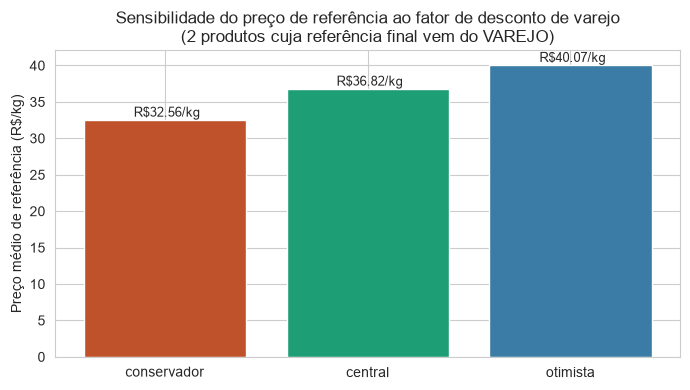

Gráfico salvo em: output/sensibilidade_desconto_varejo.png
✓ sensibilidade_desconto_varejo.csv


In [30]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 12D — SENSIBILIDADE DO FATOR DE DESCONTO DE VAREJO
# ═══════════════════════════════════════════════════════════════════════════

produtos_afetados_varejo = df_resumo[df_resumo["nivel_ref"] == "VAREJO"].copy()
n_afetados = len(produtos_afetados_varejo)
n_total = len(df_resumo)

print(f"Produtos cujo preço de referência final vem do VAREJO: {n_afetados} de {n_total} "
      f"({100 * n_afetados / max(n_total, 1):.1f}%)")

if n_afetados == 0:
    print("Nenhum produto depende do fator de desconto de varejo no momento — "
          "a análise de sensibilidade não se aplica a esta execução.")
else:
    # Reconstrói o preço de varejo SEM desconto (exato — ver nota na célula de markdown)
    produtos_afetados_varejo["preco_kg_varejo_bruto"] = (
        produtos_afetados_varejo["preco_kg_referencia"] / FATOR_DESCONTO_VAREJO
    )

    tabela_sensibilidade = produtos_afetados_varejo[["produto_busca", "preco_kg_referencia"]].copy()
    tabela_sensibilidade = tabela_sensibilidade.rename(
        columns={"preco_kg_referencia": f"preco_atual (cenario={CENARIO_VAREJO_ATIVO})"}
    )

    for nome_cenario, fator_cenario in FATOR_DESCONTO_VAREJO_CENARIOS.items():
        tabela_sensibilidade[f"preco_cenario_{nome_cenario}"] = (
            produtos_afetados_varejo["preco_kg_varejo_bruto"] * fator_cenario
        ).round(4)

    # Variação percentual de cada cenário extremo em relação ao cenário central
    fator_central = FATOR_DESCONTO_VAREJO_CENARIOS["central"]
    for nome_cenario in ["conservador", "otimista"]:
        fator_cenario = FATOR_DESCONTO_VAREJO_CENARIOS[nome_cenario]
        variacao_pct = 100 * (fator_cenario - fator_central) / fator_central
        print(f"Cenário '{nome_cenario}' (fator={fator_cenario}): "
              f"{variacao_pct:+.1f}% no preço de referência dos {n_afetados} produtos afetados, "
              f"em relação ao cenário central (fator={fator_central}).")

    print("\nTabela completa por produto:")
    display(tabela_sensibilidade.sort_values("produto_busca").reset_index(drop=True))

    # Visualização: preço médio dos produtos afetados em cada cenário
    medias_por_cenario = {
        nome: tabela_sensibilidade[f"preco_cenario_{nome}"].mean()
        for nome in FATOR_DESCONTO_VAREJO_CENARIOS
    }
    fig, ax = plt.subplots(figsize=(7, 4))
    cores_cenario = {"conservador": "#C0522B", "central": "#1D9E75", "otimista": "#3A7CA5"}
    ax.bar(
        list(medias_por_cenario.keys()),
        list(medias_por_cenario.values()),
        color=[cores_cenario.get(k, "#888780") for k in medias_por_cenario],
    )
    for i, (nome, valor) in enumerate(medias_por_cenario.items()):
        ax.text(i, valor, f" R${valor:.2f}/kg", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Preço médio de referência (R$/kg)")
    ax.set_title(
        f"Sensibilidade do preço de referência ao fator de desconto de varejo\n"
        f"({n_afetados} produtos cuja referência final vem do VAREJO)"
    )
    plt.tight_layout()
    plt.savefig(output_folder + "sensibilidade_desconto_varejo.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Gráfico salvo em: output/sensibilidade_desconto_varejo.png")

    tabela_sensibilidade.to_csv(
        output_folder + "sensibilidade_desconto_varejo.csv",
        index=False, encoding="utf-8-sig"
    )
    print("✓ sensibilidade_desconto_varejo.csv")


<a id="10"></a>
## 10. Cobertura estimada de Agricultura Familiar (Bloco 13)

Quantifica, sobre o resumo final, quantos produtos têm elegibilidade estimada via PGPM, via categoria tipicamente fornecida pela AF (heurística), ou sem evidência de compatibilidade — além de quantos têm origem regional disponível como critério de desempate. **Estes números indicam compatibilidade categórica do cardápio com a exigência de compra mínima de Agricultura Familiar do PNAE, não uma confirmação de que a compra efetiva será feita de fornecedores certificados** — essa verificação ocorre apenas no momento da chamada pública. Ver seção 13 (Limitações) para a discussão completa.



In [31]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 13 — ANÁLISE DE COBERTURA ESTIMADA DE AGRICULTURA FAMILIAR
# ═══════════════════════════════════════════════════════════════════════════

print("=== Elegibilidade estimada de Agricultura Familiar no cardápio ===\n")
print("IMPORTANTE: nenhuma fonte de preço (CONAB ou manual) identifica o perfil")
print("do fornecedor. Os valores abaixo indicam COMPATIBILIDADE categórica do")
print("produto com aquisição via Agricultura Familiar — não confirmação de")
print("origem. Ver seção 13 (Limitações) para a justificativa completa.\n")

total          = len(df_resumo)
af_pgpm        = df_resumo[(df_resumo["is_af"] == True) & (df_resumo["base_af"] == "pgpm")]
af_heuristico  = df_resumo[(df_resumo["is_af"] == True) & (df_resumo["base_af"] == "heuristico")]
nao_af         = df_resumo[df_resumo["is_af"] != True]
regionais      = df_resumo[df_resumo["origem_regional_disponivel"] == True]

print(f"Total de produtos com preço:                {total}")
print(f"Elegível — presente no PGPM:                {len(af_pgpm):>4}  ({100*len(af_pgpm)/max(total,1):.1f}%)")
print(f"Elegível — categoria tipicamente AF:        {len(af_heuristico):>4}  ({100*len(af_heuristico)/max(total,1):.1f}%)")
print(f"Elegibilidade não verificável:               {len(nao_af):>4}  ({100*len(nao_af)/max(total,1):.1f}%)")
print(f"Com origem regional (BA+vizinhos):          {len(regionais):>4}  ({100*len(regionais)/max(total,1):.1f}%)")

print("\n— Produtos elegíveis via PGPM —")
display(af_pgpm[["produto_busca", "preco_kg_referencia", "fonte_ref", "base_af", "origem_regional_disponivel"]])

print("\n— Produtos elegíveis via categoria tipicamente AF (heurística) —")
display(af_heuristico[["produto_busca", "preco_kg_referencia", "fonte_ref", "base_af", "origem_regional_disponivel"]])

print("\n— Produtos com origem regional disponível (bônus desempate) —")
display(regionais[["produto_busca", "preco_kg_referencia", "is_af", "base_af", "fonte_ref"]])


=== Elegibilidade estimada de Agricultura Familiar no cardápio ===

IMPORTANTE: nenhuma fonte de preço (CONAB ou manual) identifica o perfil
do fornecedor. Os valores abaixo indicam COMPATIBILIDADE categórica do
produto com aquisição via Agricultura Familiar — não confirmação de
origem. Ver seção 13 (Limitações) para a justificativa completa.

Total de produtos com preço:                307
Elegível — presente no PGPM:                  24  (7.8%)
Elegível — categoria tipicamente AF:          57  (18.6%)
Elegibilidade não verificável:                226  (73.6%)
Com origem regional (BA+vizinhos):           117  (38.1%)

— Produtos elegíveis via PGPM —


,produto_busca,preco_kg_referencia,fonte_ref,base_af,origem_regional_disponivel
59,cacau,8.5026,conab3,pgpm,True
60,cafe,65.9400,conab1,pgpm,True
113,farinha de mandioca,5.4200,conab1,pgpm,True
117,farinha de trigo,3.7738,conab1,pgpm,True
122,feijao preto,6.2367,conab1,pgpm,True
161,laranja baia,3.2530,conab3,pgpm,True
162,laranja lima,4.7568,conab3,pgpm,True
163,laranja pera,3.0862,conab3,pgpm,True
164,laranja valencia,3.1606,conab3,pgpm,True
167,leite de coco,1.2880,conab2,pgpm,True



— Produtos elegíveis via categoria tipicamente AF (heurística) —


,produto_busca,preco_kg_referencia,fonte_ref,base_af,origem_regional_disponivel
5,abobora moranga,2.3405,conab3,heuristico,True
7,abobrinha italiana,2.2176,conab3,heuristico,True
11,acelga,1.9433,conab3,heuristico,True
12,acerola,6.7212,conab3,heuristico,True
20,alface americana,6.0000,conab3,heuristico,True
21,alface crespa,5.7200,conab3,heuristico,True
22,alface lisa,6.0000,conab3,heuristico,True
23,alface roxa,6.0000,conab3,heuristico,True
24,alho,27.6431,conab3,heuristico,True
43,banana da terra,5.8623,conab3,heuristico,True



— Produtos com origem regional disponível (bônus desempate) —


,produto_busca,preco_kg_referencia,is_af,base_af,fonte_ref
0,abacate,4.2428,incerto,nao_verificavel,conab3
1,abacaxi,3.8010,incerto,nao_verificavel,conab3
5,abobora moranga,2.3405,True,heuristico,conab3
7,abobrinha italiana,2.2176,True,heuristico,conab3
11,acelga,1.9433,True,heuristico,conab3
12,acerola,6.7212,True,heuristico,conab3
20,alface americana,6.0000,True,heuristico,conab3
21,alface crespa,5.7200,True,heuristico,conab3
22,alface lisa,6.0000,True,heuristico,conab3
23,alface roxa,6.0000,True,heuristico,conab3


<a id="11"></a>
## 11. Visualizações

### 11.1 Sazonalidade dos principais produtos (Bloco 14)

Painel com os 12 produtos de maior variação sazonal, destacando em vermelho os meses acima de 15% da média (caros) e em verde os meses abaixo de 15% (baratos).


findfont: Failed to find font weight 500, now using 400.


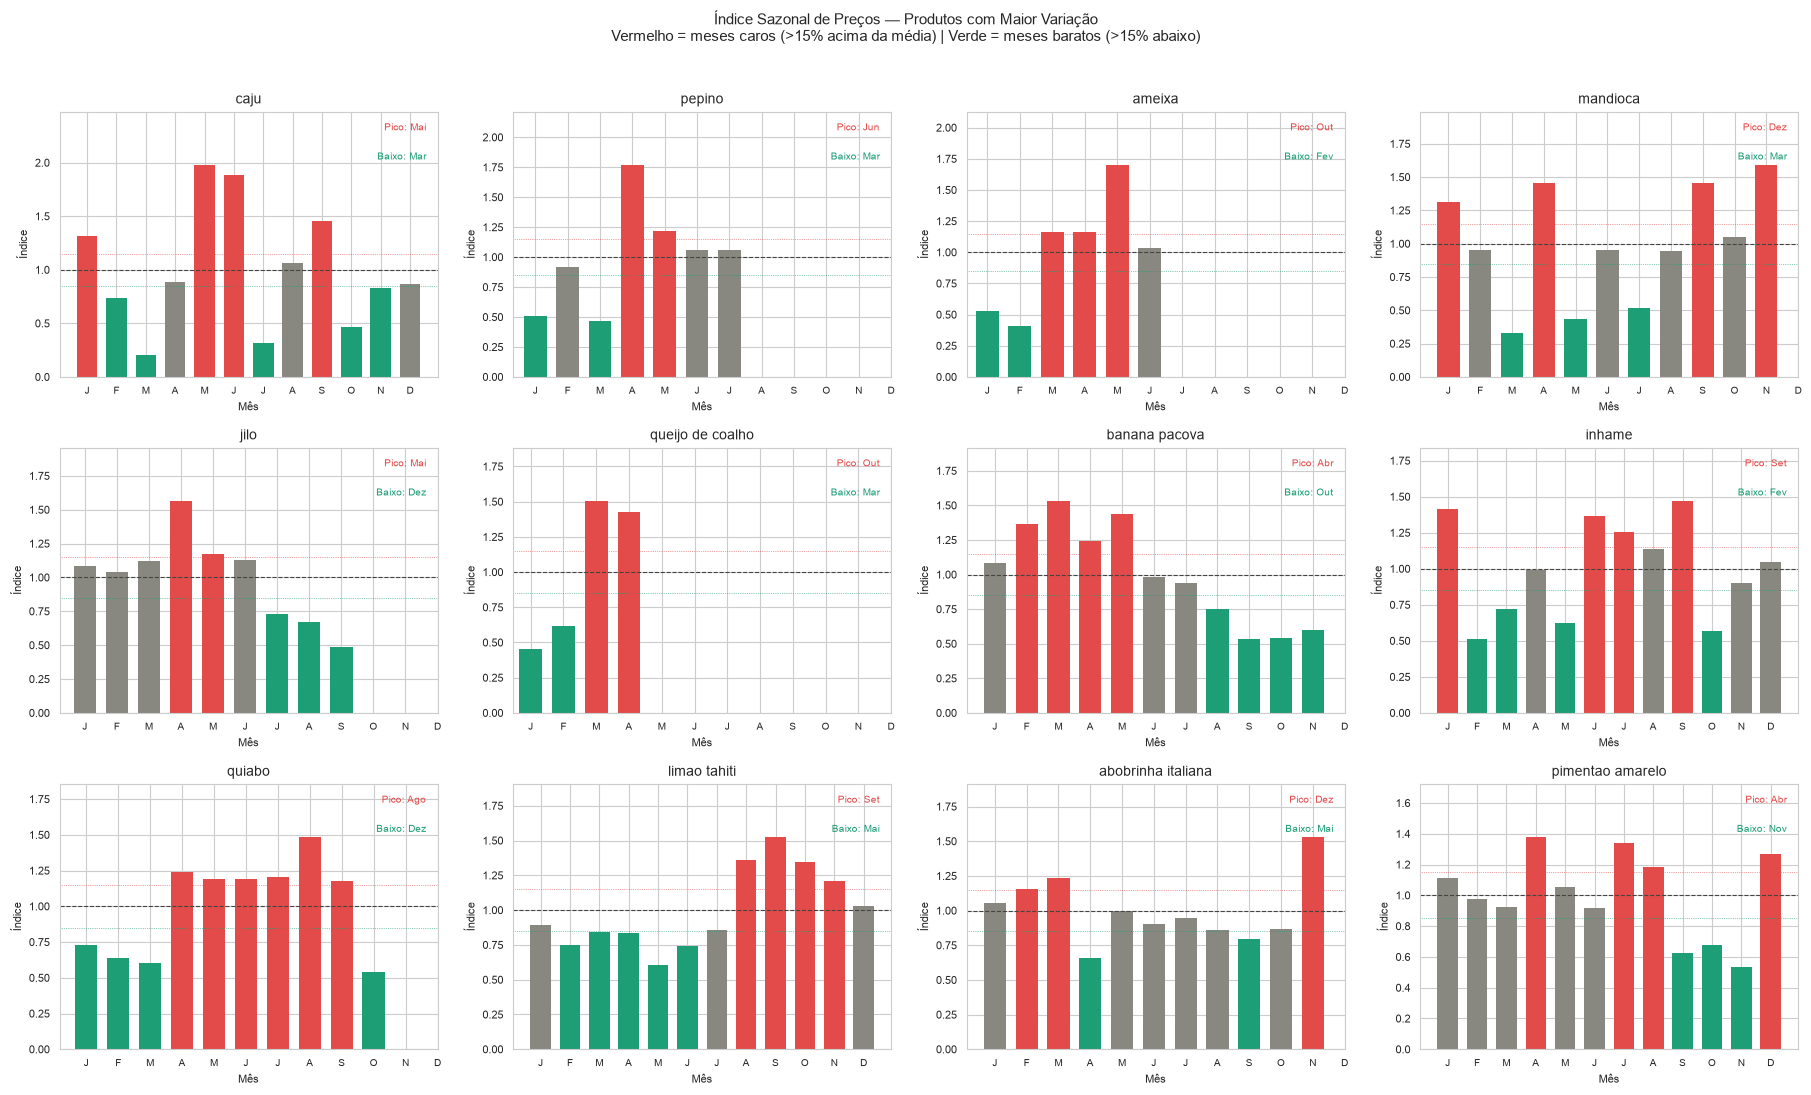

Gráfico salvo em: output/sazonalidade_precos.png


In [32]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 14 — VISUALIZAÇÃO: SAZONALIDADE DOS PRINCIPAIS PRODUTOS
# ═══════════════════════════════════════════════════════════════════════════

if not df_sazonalidade.empty and len(df_sazonalidade) > 0:
    # Selecionar produtos com maior variação sazonal para o gráfico
    top_sazonal = df_sazonalidade.nlargest(min(12, len(df_sazonalidade)), 'variacao_sazonal_pct')

    fig, axes = plt.subplots(
        nrows=3, ncols=4, figsize=(18, 10), sharey=False,
        constrained_layout=True
    )

    fig.set_constrained_layout_pads(hspace=0.05, wspace=0.05)
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, top_sazonal.iterrows()):
        indices = row['indice_sazonal_por_mes']
        if not indices:
            ax.set_visible(False)
            continue

        meses  = list(indices.keys())
        valores = list(indices.values())
        cores  = ['#E24B4A' if v > 1.15 else ('#1D9E75' if v < 0.85 else '#888780') for v in valores]

        ax.bar(range(1, len(meses)+1), valores, color=cores, width=0.7, edgecolor='none')
        ax.axhline(1.0, color='#444441', linewidth=0.8, linestyle='--')
        ax.axhline(1.15, color='#E24B4A', linewidth=0.5, linestyle=':')
        ax.axhline(0.85, color='#1D9E75', linewidth=0.5, linestyle=':')

        ax.set_title(row['produto_busca'][:28], fontsize=10, fontweight='500')
        ax.set_xlabel('Mês', fontsize=8)
        ax.set_ylabel('Índice', fontsize=8)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'], fontsize=7)
        ax.set_ylim(0, max(valores) * 1.25)
        ax.tick_params(axis='y', labelsize=8)

        # Anotação do mês de pico e baixa
        ax.annotate(f"Pico: {row['nome_mes_pico']}",
                    xy=(0.97, 0.93), xycoords='axes fraction',
                    ha='right', fontsize=7, color='#E24B4A')
        ax.annotate(f"Baixo: {row['nome_mes_baixo']}",
                    xy=(0.97, 0.82), xycoords='axes fraction',
                    ha='right', fontsize=7, color='#1D9E75')

    for ax in axes[len(top_sazonal):]:
        ax.set_visible(False)

    fig.suptitle(
        'Índice Sazonal de Preços — Produtos com Maior Variação\n'
        'Vermelho = meses caros (>15% acima da média) | Verde = meses baratos (>15% abaixo)',
        fontsize=11, y=1.08
    )
    plt.savefig(output_folder + 'sazonalidade_precos.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gráfico salvo em: output/sazonalidade_precos.png")
else:
    print("Dados insuficientes para gráfico de sazonalidade.")

### 11.2 Mapa de preços de referência por produto (Bloco 15)

Ranking dos 30 produtos de menor preço de referência, com barras de erro indicando a faixa mín./máx. observada entre fontes, cor indicando classificação de Agricultura Familiar e símbolo indicando o nível de confiança do match.


C:\Users\dba14\AppData\Local\Temp\ipykernel_10148\1450087585.py:39: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\dba14\AppData\Local\Temp\ipykernel_10148\1450087585.py:39: UserWarning: Glyph 9670 (\N{BLACK DIAMOND}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\dba14\AppData\Local\Temp\ipykernel_10148\1450087585.py:40: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.savefig(output_folder + 'precos_referencia.png', dpi=150, bbox_inches='tight')
C:\Users\dba14\AppData\Local\Temp\ipykernel_10148\1450087585.py:40: UserWarning: Glyph 9670 (\N{BLACK DIAMOND}) missing from font(s) Arial.
  plt.savefig(output_folder + 'precos_referencia.png', dpi=150, bbox_inches='tight')
c:\Users\dba14\Documents\projeto\PNAE\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dba14\Documents\proje

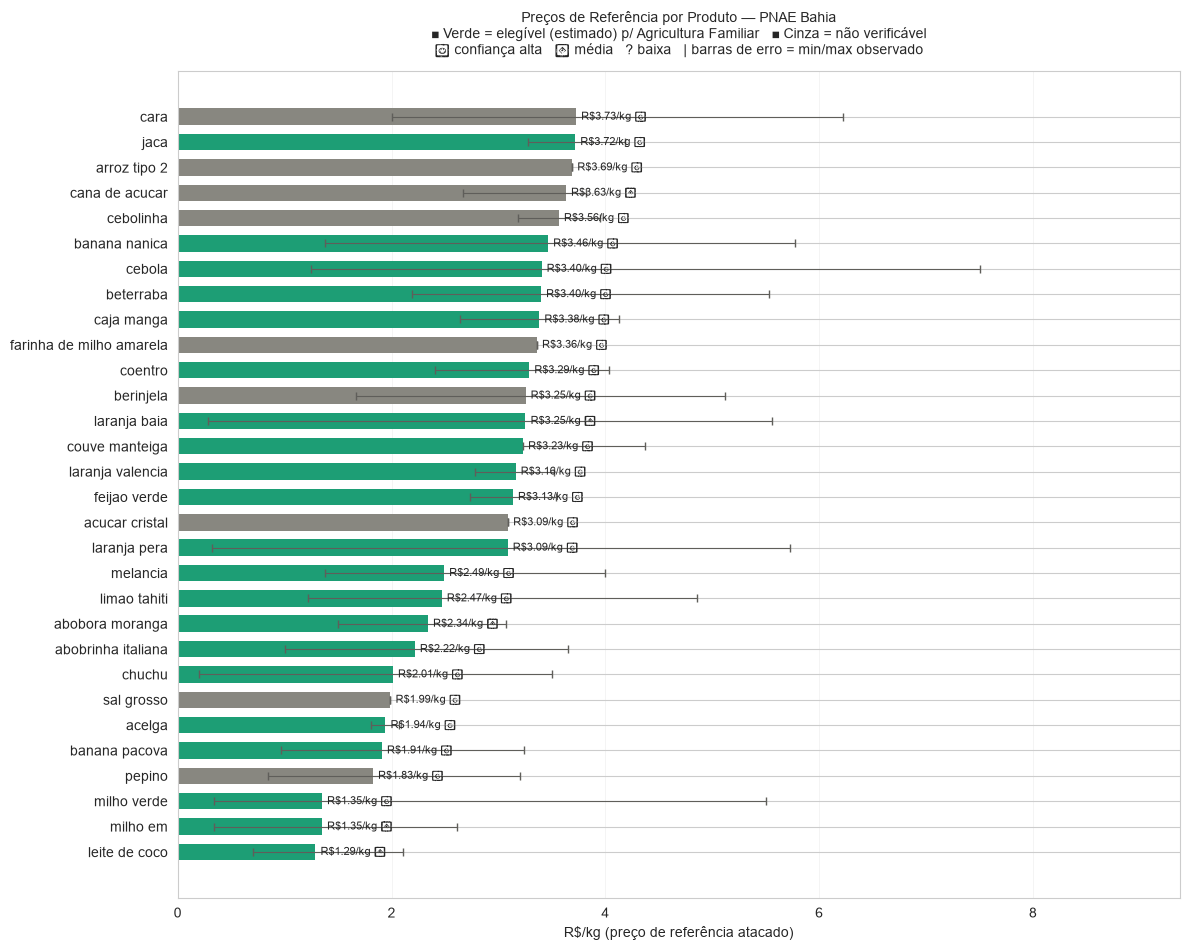

Gráfico salvo em: output/precos_referencia.png


In [33]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 15 — VISUALIZAÇÃO: MAPA DE PREÇO DE REFERÊNCIA POR PRODUTO
# ═══════════════════════════════════════════════════════════════════════════

if not df_resumo.empty:
    df_plot = df_resumo.sort_values('preco_kg_referencia', ascending=True).head(30).copy()

    cores_af = {True: '#1D9E75', 'incerto': '#888780'}
    cores = df_plot['is_af'].map(cores_af).fillna('#888780')

    fig, ax = plt.subplots(figsize=(12, max(6, len(df_plot) * 0.32)))
    bars = ax.barh(df_plot['produto_busca'], df_plot['preco_kg_referencia'],
                   color=cores, edgecolor='none', height=0.65)

    # Barras de erro para min/max
    xerr_low  = df_plot['preco_kg_referencia'] - df_plot['preco_kg_min']
    xerr_high = df_plot['preco_kg_max'] - df_plot['preco_kg_referencia']
    ax.errorbar(
        df_plot['preco_kg_referencia'], range(len(df_plot)),
        xerr=[xerr_low, xerr_high],
        fmt='none', color='#5F5E5A', capsize=3, linewidth=0.8
    )

    # Rótulos de valor
    for i, (val, conf) in enumerate(zip(df_plot['preco_kg_referencia'], df_plot['confianca_match'])):
        simbolo = '★' if conf == 'alta' else ('◆' if conf == 'media' else '?')
        ax.text(val + 0.02, i, f" R${val:.2f}/kg {simbolo}", va='center', fontsize=8)

    ax.set_xlabel('R$/kg (preço de referência atacado)', fontsize=10)
    ax.set_title(
        'Preços de Referência por Produto — PNAE Bahia\n'
        '■ Verde = elegível (estimado) p/ Agricultura Familiar   ■ Cinza = não verificável\n'
        '★ confiança alta   ◆ média   ? baixa   | barras de erro = min/max observado',
        fontsize=10, pad=12
    )
    ax.grid(axis='x', alpha=0.3, linewidth=0.5)
    ax.set_xlim(0, df_plot['preco_kg_max'].max() * 1.25)

    plt.tight_layout()
    plt.savefig(output_folder + 'precos_referencia.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gráfico salvo em: output/precos_referencia.png")

### 11.3 Alertas de sazonalidade para o planejador (Bloco 16)

Lista tabular, ordenada pela maior variação sazonal, dos produtos que apresentam algum mês com preço 15% acima da média — pensada para consumo direto por quem planeja o calendário de compras.


In [34]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 16 — ALERTAS DE SAZONALIDADE PARA O PLANEJADOR
# ═══════════════════════════════════════════════════════════════════════════

if not df_sazonalidade.empty:
    df_alertas = df_sazonalidade[df_sazonalidade['meses_alerta_preco_alto'].apply(len) > 0].copy()
    df_alertas = df_alertas.sort_values('variacao_sazonal_pct', ascending=False)

    print(f"Produtos com alertas de sazonalidade (preço >15% acima da média em algum mês): {len(df_alertas)}\n")
    display(df_alertas[[
        'produto_busca', 'nome_mes_pico', 'nome_mes_baixo',
        'nomes_meses_alerta', 'variacao_sazonal_pct'
    ]].rename(columns={
        'produto_busca':         'Produto',
        'nome_mes_pico':         'Mês mais caro',
        'nome_mes_baixo':        'Mês mais barato',
        'nomes_meses_alerta':    'Evitar compra em',
        'variacao_sazonal_pct':  'Variação sazonal (%)',
    }))
else:
    print("Nenhum dado sazonal disponível para gerar alertas.")

Produtos com alertas de sazonalidade (preço >15% acima da média em algum mês): 48



,Produto,Mês mais caro,Mês mais barato,Evitar compra em,Variação sazonal (%)
26,caju,Mai,Mar,"[Jan, Mai, Jun, Set]",177.2
87,pepino,Jun,Mar,"[Jun, Jul]",130.3
12,ameixa,Out,Fev,"[Mar, Ago, Out]",129.1
69,mandioca,Dez,Mar,"[Jan, Abr, Out, Dez]",126.1
59,jilo,Mai,Dez,"[Mai, Jun]",107.9
95,queijo de coalho,Out,Mar,"[Out, Dez]",105.4
18,banana pacova,Abr,Out,"[Mar, Abr, Mai, Jun]",99.6
54,inhame,Set,Fev,"[Jan, Jun, Jul, Set]",96.0
98,quiabo,Ago,Dez,"[Abr, Mai, Jun, Jul, Ago, Nov]",94.3
65,limao tahiti,Set,Mai,"[Ago, Set, Out, Nov]",92.0


<a id="12"></a>
## 12. Exportação dos arquivos de saída (Bloco 17)

Persiste todos os artefatos gerados em `data/output/`, mantendo exatamente os mesmos nomes de arquivo e formato (`utf-8-sig`) já em uso pelo pipeline, para preservar a compatibilidade com o Módulo 3:

| Arquivo | Conteúdo | Granularidade |
|---|---|---|
| `resultado_matching_precos.csv` | Todos os matches encontrados | série temporal completa |
| `resumo_precos_referencia.csv` | Preço de referência consolidado | uma linha por produto |
| `sazonalidade_por_produto.csv` | Índice sazonal mensal | uma linha por produto |
| `produtos_sem_preco.csv` | Alimentos do PNAE sem match em nenhuma fonte (CONAB + manual) | uma linha por produto |
| `produtos_aptos_solver.csv` | Base final de produtos elegíveis **com preço garantido** — filtro de referência (Bloco 12C) para o Módulo 4 | uma linha por produto |
| `alertas_sazonalidade.csv` | Produtos com pico de preço `>15%` da média | uma linha por produto |


In [35]:
# ═══════════════════════════════════════════════════════════════════════════
# BLOCO 17 — SALVAR TODOS OS OUTPUTS
# ═══════════════════════════════════════════════════════════════════════════

# 1. Todos os matches (série temporal completa — input para análises futuras)
df_resultado.to_csv(
    output_folder + "resultado_matching_precos.csv",
    index=False, encoding="utf-8-sig"
)
print("✓ resultado_matching_precos.csv")

# 2. Resumo consolidado — uma linha por produto (input direto para o otimizador)
df_resumo.to_csv(
    output_folder + "resumo_precos_referencia.csv",
    index=False, encoding="utf-8-sig"
)
print("✓ resumo_precos_referencia.csv")

# 3. Sazonalidade detalhada por produto
if not df_sazonalidade.empty:
    df_sazonalidade.to_csv(
        output_folder + "sazonalidade_por_produto.csv",
        index=False, encoding="utf-8-sig"
    )
    print("✓ sazonalidade_por_produto.csv")

# 4. Produtos sem preço — para curadoria manual ou fallback
# CORREÇÃO (jul/2026): usar a variável 'sem_preco' já atualizada pelo Bloco 12B
# (fallback de planilha manual), em vez de recalcular do zero via produtos_sem_match().
# Recalcular aqui ignoraria os produtos já cobertos pela planilha manual e
# reintroduziria no CSV itens que já têm preço de referência.
df_sem_preco = sem_preco.to_frame(name="produto_sem_match")
df_sem_preco.to_csv(
    output_folder + "produtos_sem_preco.csv",
    index=False, encoding="utf-8-sig"
)
print("✓ produtos_sem_preco.csv")

# 4B. Base final de produtos aptos ao solver — complemento de produtos_sem_preco.csv
# (jul/2026): consolidada e validada no Bloco 12C. Contém exatamente os
# produtos elegíveis (pode_precificar == True) que possuem preço de
# referência garantido (CONAB e/ou planilha manual), servindo como filtro
# de referência (inner join por produto_base) para o Módulo 4 — evitando
# que produtos sem preço permaneçam como variáveis de decisão válidas no
# solver por causa de um eventual left join a jusante.
df_produtos_aptos_solver.to_csv(
    output_folder + "produtos_aptos_solver.csv",
    index=False, encoding="utf-8-sig"
)
print("✓ produtos_aptos_solver.csv")

# 5. Lista de alertas sazonais
if not df_sazonalidade.empty:
    df_alertas_save = df_sazonalidade[df_sazonalidade['meses_alerta_preco_alto'].apply(len) > 0]
    df_alertas_save.to_csv(
        output_folder + "alertas_sazonalidade.csv",
        index=False, encoding="utf-8-sig"
    )
    print("✓ alertas_sazonalidade.csv")

print("\nTodos os arquivos salvos em:", output_folder)
print("\nResumo final das colunas do arquivo para o otimizador (resumo_precos_referencia.csv):")
if not df_resumo.empty:
    display(pd.DataFrame({
        'coluna': df_resumo.columns.tolist(),
        'dtype': [str(df_resumo[c].dtype) for c in df_resumo.columns],
        'exemplo': [str(df_resumo[c].iloc[0]) if len(df_resumo) > 0 else '' for c in df_resumo.columns],
    }))

✓ resultado_matching_precos.csv
✓ resumo_precos_referencia.csv
✓ sazonalidade_por_produto.csv
✓ produtos_sem_preco.csv
✓ produtos_aptos_solver.csv
✓ alertas_sazonalidade.csv

Todos os arquivos salvos em: ./data/output/

Resumo final das colunas do arquivo para o otimizador (resumo_precos_referencia.csv):


,coluna,dtype,exemplo
0,produto_busca,str,abacate
1,produto_encontrado_ref,str,ABACATE
2,fonte_ref,str,conab3
3,nivel_ref,str,PROHORT
4,prioridade_ref,int64,3
5,score_match_ref,float64,1.0
6,confianca_match,str,alta
7,via_mapeamento_fixo,bool,False
8,preco_kg_referencia,float64,4.2428
9,preco_kg_min,float64,2.0


<a id="13"></a>
## 13. Conclusão, limitações e próximos passos

### O que este notebook entrega

Um preço de referência por kg, rastreável e classificado quanto à confiança do match e à **elegibilidade estimada** de Agricultura Familiar, para os alimentos elegíveis do cardápio PNAE — pronto para ser consumido pelo modelo de Programação Linear (`resumo_precos_referencia.csv`), com evidências de sazonalidade que podem informar restrições adicionais de calendário de compras.

### Correções aplicadas nesta revisão (set/2026)

- **Bug crítico corrigido — classificação de Agricultura Familiar:** uma string vazia em `produtos_pgpm_norm`, originada de um registro em branco na base bruta do Conab2, fazia `is_produto_no_pgpm()` retornar sempre `True` (confirmado empiricamente: 100% dos matches CONAB classificados como AF antes da correção; nível heurístico nunca acionado). Corrigido filtrando entradas com menos de 3 caracteres.
- **Limiares de matching corrigidos:** `THRESHOLD_ACEITO` (0,72) e o antigo `THRESHOLD_CONFIAVEL` (0,55) estavam invertidos, fazendo com que 100% dos matches aceitos caíssem em confiança 'alta' (nível 'media' nunca ocorria). Correção conservadora: `THRESHOLD_ACEITO` mantido em 0,72 (preserva a população de matches já usada nos Resultados Preliminares — VII Evento); novo `THRESHOLD_ALTA_CONFIANCA` (0,85, estimativa inicial) diferencia 'alta' de 'media' dentro do conjunto já aceito.
- **Reformulação metodológica da classificação de AF (Opção 3, validada com a autora):** nenhuma fonte CONAB identifica o perfil do fornecedor — a PGPM cobre produtores em geral, não exclusivamente a Agricultura Familiar (a lista da Bahia inclui, inclusive, commodities patronais/extrativistas como algodão em pluma e borracha natural). O campo `is_af` permanece binário para uso do solver, mas a antiga hierarquia de "confiança" (alta/media/baixa) foi removida — substituída por `base_af` (`pgpm` / `heuristico` / `nao_verificavel`), que documenta a evidência sem alegar confirmação de origem.
- **Fator de desconto de varejo fundamentado e parametrizado:** o valor antes fixo (0,72, sem citação, com comentário de código divergente — "30%" no texto vs. 28% no valor real) foi substituído por `FATOR_DESCONTO_VAREJO_CENARIOS`, com o cenário central (0,735) baseado na margem de comercialização do comércio varejista (hipermercados/supermercados) de 26,5% — IBGE, Pesquisa Anual do Comércio, Tabela 10645, ano-base 2024 (dado de 2025 ainda não divulgado). Ver seção 9D para a análise de sensibilidade entre os cenários conservador/central/otimista.
- **Célula de normalização exploratória do Conab2 (antiga seção 4.2)** marcada explicitamente como não utilizada nas etapas seguintes e com colunas renomeadas (sufixo `_exploratorio`), evitando que seus valores fossem confundidos com o `preco_kg` efetivamente usado no pipeline (calculado na seção 5.4).
- **Constante `MIN_WORD_OVERLAP`** mantida como parâmetro reservado, com nota explícita de que não está implementada em nenhuma regra de matching.
- **Clareza sobre contagens:** anotado explicitamente por que "alimentos elegíveis" (seção 3, contagem de linhas) e "produto_busca únicos" (seção 9C) podem diferir — mapeamento n:1 entre preparações/variações e a chave de busca textual.

### Limitações conhecidas

- **Recorte geográfico:** o pipeline está parametrizado para a Bahia (`uf == 'BA'`); a generalização para outros estados exige apenas trocar esse filtro nas seções 4.1–4.3, mas não foi testada.
- **Elegibilidade de Agricultura Familiar é uma estimativa categórica, não uma confirmação:** nenhuma base de preço (CONAB ou manual) identifica o perfil do fornecedor. Os campos `is_af`/`base_af` indicam apenas que o *tipo* de produto é compatível com aquisição via Agricultura Familiar. A verificação real (DAP/CAF do fornecedor) ocorre apenas no momento da compra (chamada pública), fora do escopo de dados deste notebook. **Recomenda-se que o TCC descreva o indicador de "% AF" do cardápio como elegibilidade estimada da composição do cardápio, não como garantia de execução da compra.**
- **Lista heurística de Agricultura Familiar** (`base_af == 'heuristico'`) é baseada em conhecimento de domínio, não em fonte oficial única — vale registrar essa premissa explicitamente no TCC.
- **Corte de `THRESHOLD_ALTA_CONFIANCA` (0,85) é uma estimativa inicial**, não calibrada contra a distribuição real de `score_match` após a reexecução completa do pipeline. Recomenda-se revisar com `df_resultado['score_match'].describe()`/`.quantile()` e validar com o orientador antes da versão final do TCC.
- **Fator de desconto de varejo (cenário central = 0,735)** é fundamentado em uma margem de comercialização nacional/setorial ampla (hipermercados e supermercados, IBGE/PAC), não específica para hortifrúti na Bahia — a análise de sensibilidade (seção 9D) existe justamente para tornar essa incerteza explícita e quantificada no TCC.
- **Produtos sem match** (`produtos_sem_preco.csv`) precisam de curadoria manual ou de uma fonte de preço complementar antes da modelagem final. Estes produtos já são explicitamente removidos da base final consumida pelo solver — ver Bloco 12C e `produtos_aptos_solver.csv`.

### Sugestões de ajuste antes da entrega final (não alteram nenhuma leitura/escrita de CSV)

- Avaliar se as células de verificação exploratória (amostra de 1% na seção 3, teste do cálculo de valor/kg na seção 4.3, e normalização preliminar do Conab2 na seção 4.2) devem permanecer no corpo principal do notebook ou migrar para um apêndice de rascunho — nenhuma delas alimenta uma etapa posterior do pipeline.
- Após a próxima execução completa, revisar a distribuição de `score_match` para validar (ou ajustar) o corte de `THRESHOLD_ALTA_CONFIANCA`.
- Buscar, se possível, uma margem de comercialização mais específica para hortifrúti/Nordeste (complementar à referência nacional do IBGE) para reforçar ainda mais a justificativa do fator de desconto de varejo.
